In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import shap
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

NASA battery files loaded successfully.
B0005: loaded
B0006: loaded
B0007: loaded
B0018: loaded

Stage 1 completed.


,battery_id,total_cycles,charge_cycles,discharge_cycles,impedance_cycles,unknown_cycles,first_capacity_ah,last_capacity_ah,capacity_fade_percent,documented_cutoff_voltage
0,B0005,616,170,168,278,0,1.856487,1.325079,28.624384,2.7
1,B0006,616,170,168,278,0,2.035338,1.185675,41.745525,2.5
2,B0007,616,170,168,278,0,1.891052,1.432455,24.250891,2.2
3,B0018,319,134,132,53,0,1.855005,1.341051,27.706298,2.5



Cycle-level dataset checks:
Total discharge records: 636
Number of batteries: 4
Duplicate battery/cycle combinations: 0
Missing capacity: 0
Missing SoH: 0

Records per battery:


,records
battery_id,
B0005,168
B0006,168
B0007,168
B0018,132



SoH range by battery:


...


Stage 2 completed: battery_soh_cycle_dataset.csv

Feature dataset shape:
(636, 30)

Records per battery:


,records
battery_id,
B0005,168
B0006,168
B0007,168
B0018,132



Missing values in 24 features:


,0
dis_voltage_q10,0
dis_voltage_q50,0
dis_voltage_q90,0
dis_voltage_iqr,0
dis_voltage_range,0
dis_voltage_std,0
dis_voltage_slope,0
dis_current_mean,0
dis_current_std,0
dis_current_range,0



Stage 3 completed: 24 engineered features created.


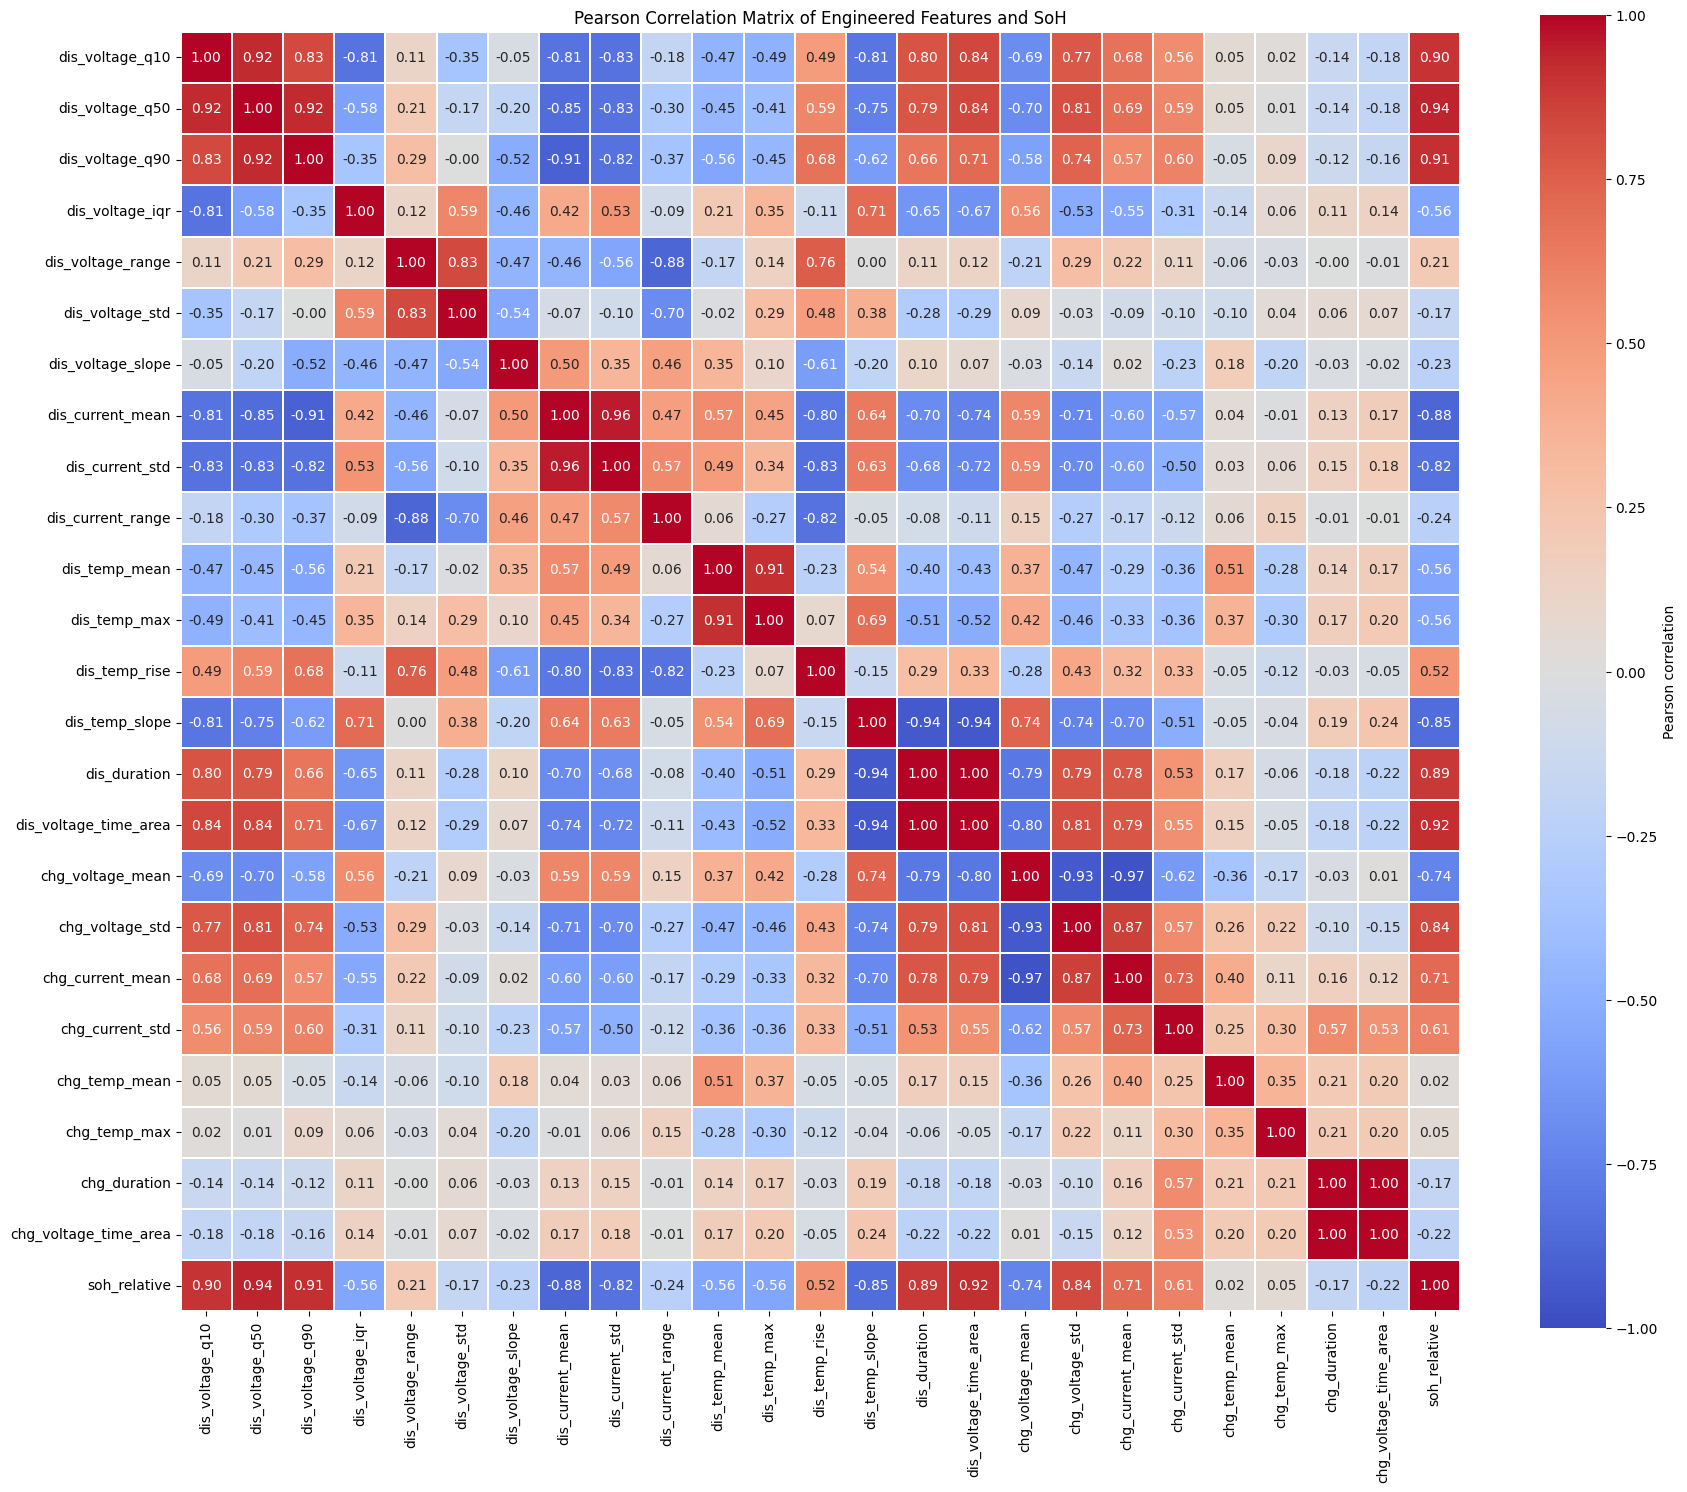


Feature correlations with SoH:


,soh_relative
dis_voltage_q50,0.9438
dis_voltage_time_area,0.9210
dis_voltage_q90,0.9082
dis_voltage_q10,0.8985
dis_duration,0.8885
dis_current_mean,-0.8819
dis_temp_slope,-0.8476
chg_voltage_std,0.8358
dis_current_std,-0.8236
chg_voltage_mean,-0.7379



AUTOMATIC FEATURE REDUCTION SUMMARY
Original features : 24
Removed features  : 9
Final features    : 15

Removed features:
- dis_voltage_q10
- dis_voltage_q90
- dis_current_std
- dis_temp_max
- dis_temp_slope
- dis_duration
- chg_voltage_mean
- chg_current_mean
- chg_duration

Retained features:
- dis_voltage_q50
- dis_voltage_iqr
- dis_voltage_range
- dis_voltage_std
- dis_voltage_slope
- dis_current_mean
- dis_current_range
- dis_temp_mean
- dis_temp_rise
- dis_voltage_time_area
- chg_voltage_std
- chg_current_std
- chg_temp_mean
- chg_temp_max
- chg_voltage_time_area

Verification successful: no feature pairs with |r| >= 0.90 remain.

COMPLETE PIPELINE FINISHED
NASA batteries processed: 4
Original engineered features: 24
Reduced features: 15


In [2]:
# NASA BATTERY SoH PROJECT
# Project setup and raw NASA data inspection

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

BATTERY_FILES = {
    "B0005": PROJECT_ROOT / "B0005.mat",
    "B0006": PROJECT_ROOT / "B0006.mat",
    "B0007": PROJECT_ROOT / "B0007.mat",
    "B0018": PROJECT_ROOT / "B0018.mat"
}

# Documented discharge cutoff voltage for each NASA battery
DISCHARGE_CUTOFFS = {
    "B0005": 2.7,
    "B0006": 2.5,
    "B0007": 2.2,
    "B0018": 2.5
}


# MATLAB helper functions

def get_field(obj, field):
    """Safely retrieve a field from a MATLAB struct."""

    if obj is None:
        return None

    if isinstance(obj, dict):
        return obj.get(field)

    if hasattr(obj, field):
        return getattr(obj, field)

    return None


def numeric_vector(value):
    """Convert MATLAB values into a clean 1-D numeric array."""

    if value is None:
        return np.array([], dtype=float)

    try:
        arr = np.asarray(value).squeeze()
        arr = np.asarray(arr, dtype=float).flatten()
        return arr[np.isfinite(arr)]

    except (TypeError, ValueError):
        return np.array([], dtype=float)


def get_cycle_type(cycle):
    """Identify whether a cycle is charge, discharge or impedance."""

    value = get_field(cycle, "type")

    if value is None:
        return ""

    if isinstance(value, np.ndarray):
        value = value.squeeze()

    if isinstance(value, bytes):
        value = value.decode(errors="ignore")

    return str(value).strip().lower()


def extract_cycle_data(cycle):
    """Extract voltage, current, temperature, time and capacity."""

    data = get_field(cycle, "data")

    if data is None:
        return {
            "voltage": np.array([], dtype=float),
            "current": np.array([], dtype=float),
            "temperature": np.array([], dtype=float),
            "time": np.array([], dtype=float),
            "capacity": np.array([], dtype=float)
        }

    return {
        "voltage": numeric_vector(
            get_field(data, "Voltage_measured")
        ),
        "current": numeric_vector(
            get_field(data, "Current_measured")
        ),
        "temperature": numeric_vector(
            get_field(data, "Temperature_measured")
        ),
        "time": numeric_vector(
            get_field(data, "Time")
        ),
        "capacity": numeric_vector(
            get_field(data, "Capacity")
        )
    }


# Check that all NASA battery files are available

for battery_id, file_path in BATTERY_FILES.items():

    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing NASA file: {file_path}"
        )


# Load the four NASA battery structures

battery_objects = {}

for battery_id, file_path in BATTERY_FILES.items():

    mat_data = loadmat(
        file_path,
        squeeze_me=True,
        struct_as_record=False
    )

    # NASA files normally use the battery ID as the top-level key
    battery = mat_data.get(battery_id)

    # Use the only available non-system key as a fallback
    if battery is None:

        possible_keys = [
            key
            for key in mat_data.keys()
            if not key.startswith("__")
        ]

        if len(possible_keys) == 1:
            battery = mat_data[possible_keys[0]]

    if battery is None:
        raise ValueError(
            f"Battery structure not found in {file_path}.\n"
            f"Available keys: "
            f"{[key for key in mat_data.keys() if not key.startswith('__')]}"
        )

    battery_objects[battery_id] = battery


print("NASA battery files loaded successfully.")

for battery_id in battery_objects:
    print(f"{battery_id}: loaded")


# Inspect charge, discharge and impedance cycles

battery_summary = []
discharge_inventory = []
matlab_structure = {}

for battery_id, battery in battery_objects.items():

    cycles = get_field(battery, "cycle")

    if cycles is None:
        raise ValueError(
            f"No 'cycle' field found for {battery_id}"
        )

    cycles = np.atleast_1d(cycles)

    charge_count = 0
    discharge_count = 0
    impedance_count = 0
    unknown_count = 0

    discharge_records = []

    for cycle_number, cycle in enumerate(cycles, start=1):

        cycle_type = get_cycle_type(cycle)

        if cycle_type == "charge":

            charge_count += 1

        elif cycle_type == "discharge":

            discharge_count += 1

            signals = extract_cycle_data(cycle)

            voltage = signals["voltage"]
            temperature = signals["temperature"]
            time = signals["time"]
            capacity = signals["capacity"]

            valid_capacity = capacity[
                np.isfinite(capacity)
            ]

            final_capacity = (
                valid_capacity[-1]
                if len(valid_capacity) > 0
                else np.nan
            )

            duration = (
                time[-1] - time[0]
                if len(time) >= 2
                else np.nan
            )

            discharge_records.append({
                "battery_id": battery_id,
                "cycle_number": cycle_number,
                "capacity_ah": final_capacity,
                "duration_seconds": duration,
                "voltage_min": (
                    np.min(voltage)
                    if len(voltage)
                    else np.nan
                ),
                "voltage_max": (
                    np.max(voltage)
                    if len(voltage)
                    else np.nan
                ),
                "temperature_min": (
                    np.min(temperature)
                    if len(temperature)
                    else np.nan
                ),
                "temperature_max": (
                    np.max(temperature)
                    if len(temperature)
                    else np.nan
                ),
                "measurement_count": len(voltage)
            })

        elif cycle_type == "impedance":

            impedance_count += 1

        else:

            unknown_count += 1

    # Calculate capacity fade from the first and last valid discharge
    valid_capacities = [
        row["capacity_ah"]
        for row in discharge_records
        if pd.notna(row["capacity_ah"])
    ]

    first_capacity = (
        valid_capacities[0]
        if valid_capacities
        else np.nan
    )

    last_capacity = (
        valid_capacities[-1]
        if valid_capacities
        else np.nan
    )

    if (
        pd.notna(first_capacity)
        and first_capacity != 0
        and pd.notna(last_capacity)
    ):

        capacity_fade = (
            (first_capacity - last_capacity)
            / first_capacity
            * 100
        )

    else:

        capacity_fade = np.nan

    battery_summary.append({
        "battery_id": battery_id,
        "total_cycles": len(cycles),
        "charge_cycles": charge_count,
        "discharge_cycles": discharge_count,
        "impedance_cycles": impedance_count,
        "unknown_cycles": unknown_count,
        "first_capacity_ah": first_capacity,
        "last_capacity_ah": last_capacity,
        "capacity_fade_percent": capacity_fade,
        "documented_cutoff_voltage":
            DISCHARGE_CUTOFFS[battery_id]
    })

    discharge_inventory.extend(discharge_records)

    matlab_structure[battery_id] = {
        "number_of_cycles": len(cycles),
        "cycle_types": {
            "charge": charge_count,
            "discharge": discharge_count,
            "impedance": impedance_count,
            "unknown": unknown_count
        }
    }


# Save raw inspection results

pd.DataFrame(
    battery_summary
).to_csv(
    OUTPUT_DIR / "battery_summary.csv",
    index=False
)

pd.DataFrame(
    discharge_inventory
).to_csv(
    OUTPUT_DIR / "discharge_cycle_inventory.csv",
    index=False
)

with open(
    OUTPUT_DIR / "matlab_structure.json",
    "w"
) as f:

    json.dump(
        matlab_structure,
        f,
        indent=2
    )

print("\nStage 1 completed.")

display(
    pd.DataFrame(battery_summary)
)


# Stage 2: create the cycle-level SoH dataset

cycle_records = []

for battery_id, battery in battery_objects.items():

    cycles = np.atleast_1d(
        get_field(battery, "cycle")
    )

    latest_charge = None
    latest_charge_number = None

    for cycle_number, cycle in enumerate(cycles, start=1):

        cycle_type = get_cycle_type(cycle)

        # Store the most recent charge cycle
        if cycle_type == "charge":

            latest_charge = extract_cycle_data(cycle)
            latest_charge_number = cycle_number

        # Use each valid discharge cycle to create one SoH record
        elif cycle_type == "discharge":

            discharge = extract_cycle_data(cycle)

            capacity = discharge["capacity"]

            valid_capacity = capacity[
                np.isfinite(capacity)
            ]

            if len(valid_capacity) == 0:
                continue

            final_capacity = valid_capacity[-1]

            discharge_time = discharge["time"]

            discharge_duration = (
                discharge_time[-1]
                - discharge_time[0]
                if len(discharge_time) >= 2
                else np.nan
            )

            # Extract summary information from the preceding charge
            if latest_charge is not None:

                charge_time = latest_charge["time"]

                charge_duration = (
                    charge_time[-1]
                    - charge_time[0]
                    if len(charge_time) >= 2
                    else np.nan
                )

                charge_voltage_count = len(
                    latest_charge["voltage"]
                )

                charge_current_count = len(
                    latest_charge["current"]
                )

                charge_temperature_count = len(
                    latest_charge["temperature"]
                )

            else:

                charge_duration = np.nan
                charge_voltage_count = 0
                charge_current_count = 0
                charge_temperature_count = 0

            cycle_records.append({
                "battery_id": battery_id,
                "cycle_number": cycle_number,
                "charge_cycle_number": latest_charge_number,
                "capacity_ah": final_capacity,
                "charge_duration": charge_duration,
                "discharge_duration": discharge_duration,
                "charge_voltage_count": charge_voltage_count,
                "charge_current_count": charge_current_count,
                "charge_temperature_count": charge_temperature_count,
                "discharge_voltage_count":
                    len(discharge["voltage"]),
                "discharge_current_count":
                    len(discharge["current"]),
                "discharge_temperature_count":
                    len(discharge["temperature"])
            })


cycle_data = pd.DataFrame(cycle_records)


# Calculate relative SoH separately for each battery

cycle_data = cycle_data.sort_values(
    ["battery_id", "cycle_number"]
).reset_index(drop=True)

cycle_data["initial_capacity_ah"] = (
    cycle_data
    .groupby("battery_id")["capacity_ah"]
    .transform("first")
)

cycle_data["soh_relative"] = (
    cycle_data["capacity_ah"]
    / cycle_data["initial_capacity_ah"]
)

cycle_data["discharge_sequence"] = (
    cycle_data
    .groupby("battery_id")
    .cumcount() + 1
)


# Check the cycle-level dataset

print("\nCycle-level dataset checks:")
print("Total discharge records:", len(cycle_data))
print("Number of batteries:", cycle_data["battery_id"].nunique())

print(
    "Duplicate battery/cycle combinations:",
    cycle_data.duplicated(
        ["battery_id", "cycle_number"]
    ).sum()
)

print(
    "Missing capacity:",
    cycle_data["capacity_ah"].isna().sum()
)

print(
    "Missing SoH:",
    cycle_data["soh_relative"].isna().sum()
)

print("\nRecords per battery:")

display(
    cycle_data
    .groupby("battery_id")
    .size()
    .rename("records")
)

print("\nSoH range by battery:")

display(
    cycle_data
    .groupby("battery_id")["soh_relative"]
    .agg(["min", "max"])
)

cycle_data.to_csv(
    OUTPUT_DIR / "battery_soh_cycle_dataset.csv",
    index=False
)

print(
    "\nStage 2 completed: "
    "battery_soh_cycle_dataset.csv"
)


# Stage 3: engineer 24 battery signal features

def safe_mean(x):
    return np.mean(x) if len(x) else np.nan


def safe_std(x):
    return np.std(x, ddof=1) if len(x) > 1 else np.nan


def safe_min(x):
    return np.min(x) if len(x) else np.nan


def safe_max(x):
    return np.max(x) if len(x) else np.nan


def safe_range(x):
    return (
        np.max(x) - np.min(x)
        if len(x)
        else np.nan
    )


def safe_percentile(x, q):
    return (
        np.percentile(x, q)
        if len(x)
        else np.nan
    )


def safe_slope(x, t):
    if len(x) < 2 or len(t) != len(x):
        return np.nan

    try:
        return np.polyfit(t, x, 1)[0]
    except Exception:
        return np.nan


def safe_trapz(y, x):
    if len(y) < 2 or len(x) != len(y):
        return np.nan

    try:
        return np.trapezoid(y, x)
    except AttributeError:
        return np.trapz(y, x)


feature_records = []

for battery_id, battery in battery_objects.items():

    cycles = np.atleast_1d(
        get_field(battery, "cycle")
    )

    latest_charge = None

    for cycle_number, cycle in enumerate(cycles, start=1):

        cycle_type = get_cycle_type(cycle)

        # Store the latest charge signals
        if cycle_type == "charge":

            latest_charge = extract_cycle_data(cycle)

        elif cycle_type != "discharge":

            continue

        # Extract signals from the discharge cycle
        discharge = extract_cycle_data(cycle)

        voltage = discharge["voltage"]
        current = discharge["current"]
        temperature = discharge["temperature"]
        time = discharge["time"]
        capacity = discharge["capacity"]

        valid_capacity = capacity[
            np.isfinite(capacity)
        ]

        if len(valid_capacity) == 0:
            continue

        final_capacity = valid_capacity[-1]

        # Discharge voltage features
        dis_voltage_q10 = safe_percentile(voltage, 10)
        dis_voltage_q50 = safe_percentile(voltage, 50)
        dis_voltage_q90 = safe_percentile(voltage, 90)

        dis_voltage_iqr = (
            dis_voltage_q90 - dis_voltage_q10
            if pd.notna(dis_voltage_q90)
            and pd.notna(dis_voltage_q10)
            else np.nan
        )

        dis_voltage_range = safe_range(voltage)
        dis_voltage_std = safe_std(voltage)
        dis_voltage_slope = safe_slope(voltage, time)

        # Discharge current features
        dis_current_mean = safe_mean(current)
        dis_current_std = safe_std(current)
        dis_current_range = safe_range(current)

        # Discharge temperature features
        dis_temp_mean = safe_mean(temperature)
        dis_temp_max = safe_max(temperature)

        dis_temp_rise = (
            temperature[-1] - temperature[0]
            if len(temperature) >= 2
            else np.nan
        )

        dis_temp_slope = safe_slope(
            temperature,
            time
        )

        # Discharge profile features
        dis_duration = (
            time[-1] - time[0]
            if len(time) >= 2
            else np.nan
        )

        dis_voltage_time_area = safe_trapz(
            voltage,
            time
        )

        # Charge features from the preceding charge cycle
        if latest_charge is not None:

            chg_voltage = latest_charge["voltage"]
            chg_current = latest_charge["current"]
            chg_temperature = latest_charge["temperature"]
            chg_time = latest_charge["time"]

            chg_voltage_mean = safe_mean(chg_voltage)
            chg_voltage_std = safe_std(chg_voltage)

            chg_current_mean = safe_mean(chg_current)
            chg_current_std = safe_std(chg_current)

            chg_temp_mean = safe_mean(chg_temperature)
            chg_temp_max = safe_max(chg_temperature)

            chg_duration = (
                chg_time[-1] - chg_time[0]
                if len(chg_time) >= 2
                else np.nan
            )

            chg_voltage_time_area = safe_trapz(
                chg_voltage,
                chg_time
            )

        else:

            chg_voltage_mean = np.nan
            chg_voltage_std = np.nan
            chg_current_mean = np.nan
            chg_current_std = np.nan
            chg_temp_mean = np.nan
            chg_temp_max = np.nan
            chg_duration = np.nan
            chg_voltage_time_area = np.nan

        feature_records.append({
            "battery_id": battery_id,
            "cycle_number": cycle_number,
            "capacity_ah": final_capacity,

            "dis_voltage_q10": dis_voltage_q10,
            "dis_voltage_q50": dis_voltage_q50,
            "dis_voltage_q90": dis_voltage_q90,
            "dis_voltage_iqr": dis_voltage_iqr,
            "dis_voltage_range": dis_voltage_range,
            "dis_voltage_std": dis_voltage_std,
            "dis_voltage_slope": dis_voltage_slope,

            "dis_current_mean": dis_current_mean,
            "dis_current_std": dis_current_std,
            "dis_current_range": dis_current_range,

            "dis_temp_mean": dis_temp_mean,
            "dis_temp_max": dis_temp_max,
            "dis_temp_rise": dis_temp_rise,
            "dis_temp_slope": dis_temp_slope,

            "dis_duration": dis_duration,
            "dis_voltage_time_area":
                dis_voltage_time_area,

            "chg_voltage_mean": chg_voltage_mean,
            "chg_voltage_std": chg_voltage_std,

            "chg_current_mean": chg_current_mean,
            "chg_current_std": chg_current_std,

            "chg_temp_mean": chg_temp_mean,
            "chg_temp_max": chg_temp_max,

            "chg_duration": chg_duration,
            "chg_voltage_time_area":
                chg_voltage_time_area
        })


features = pd.DataFrame(feature_records)


# Merge the authoritative cycle-level SoH values

soh_reference = cycle_data[
    [
        "battery_id",
        "cycle_number",
        "soh_relative",
        "initial_capacity_ah",
        "discharge_sequence"
    ]
].copy()

feature_data = features.merge(
    soh_reference,
    on=["battery_id", "cycle_number"],
    how="left",
    validate="one_to_one"
)


# Define the 24 candidate predictor features

candidate_features = [
    "dis_voltage_q10",
    "dis_voltage_q50",
    "dis_voltage_q90",
    "dis_voltage_iqr",
    "dis_voltage_range",
    "dis_voltage_std",
    "dis_voltage_slope",
    "dis_current_mean",
    "dis_current_std",
    "dis_current_range",
    "dis_temp_mean",
    "dis_temp_max",
    "dis_temp_rise",
    "dis_temp_slope",
    "dis_duration",
    "dis_voltage_time_area",
    "chg_voltage_mean",
    "chg_voltage_std",
    "chg_current_mean",
    "chg_current_std",
    "chg_temp_mean",
    "chg_temp_max",
    "chg_duration",
    "chg_voltage_time_area"
]


# Check feature completeness

print("\nFeature dataset shape:")
print(feature_data.shape)

print("\nRecords per battery:")

display(
    feature_data
    .groupby("battery_id")
    .size()
    .rename("records")
)

print("\nMissing values in 24 features:")

display(
    feature_data[
        candidate_features
    ].isna().sum()
)


# Save feature statistics

feature_statistics = (
    feature_data[candidate_features]
    .describe()
    .T
)

feature_statistics["missing"] = (
    feature_data[candidate_features]
    .isna()
    .sum()
)

feature_statistics.to_csv(
    OUTPUT_DIR / "feature_statistics.csv"
)


# Save descriptions of the engineered features

feature_dictionary = pd.DataFrame({
    "feature": candidate_features,
    "description": [
        "10th percentile of discharge voltage",
        "Median of discharge voltage",
        "90th percentile of discharge voltage",
        "Interquartile range of discharge voltage",
        "Range of discharge voltage",
        "Standard deviation of discharge voltage",
        "Slope of discharge voltage over time",
        "Mean discharge current",
        "Standard deviation of discharge current",
        "Range of discharge current",
        "Mean discharge temperature",
        "Maximum discharge temperature",
        "Discharge temperature rise",
        "Slope of discharge temperature over time",
        "Discharge duration",
        "Area under discharge voltage-time curve",
        "Mean voltage during preceding charge",
        "Standard deviation of voltage during preceding charge",
        "Mean current during preceding charge",
        "Standard deviation of current during preceding charge",
        "Mean temperature during preceding charge",
        "Maximum temperature during preceding charge",
        "Preceding charge duration",
        "Area under preceding charge voltage-time curve"
    ]
})

feature_dictionary.to_csv(
    OUTPUT_DIR / "feature_dictionary.csv",
    index=False
)

feature_data.to_csv(
    OUTPUT_DIR / "battery_soh_feature_dataset.csv",
    index=False
)

print(
    "\nStage 3 completed: "
    "24 engineered features created."
)


# Stage 4: analyse feature correlations and reduce redundancy

TARGET_COLUMN = "soh_relative"

correlation_columns = (
    candidate_features + [TARGET_COLUMN]
)


# Calculate Pearson correlation matrix

correlation_matrix = feature_data[
    correlation_columns
].corr(method="pearson")

correlation_matrix.to_csv(
    OUTPUT_DIR / "complete_correlation_matrix.csv"
)

correlation_matrix.round(4).to_excel(
    OUTPUT_DIR / "complete_correlation_matrix.xlsx"
)


# Plot the complete feature correlation matrix

plt.figure(figsize=(18, 15))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.3,
    cbar_kws={
        "label": "Pearson correlation"
    }
)

plt.title(
    "Pearson Correlation Matrix "
    "of Engineered Features and SoH"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Calculate feature-to-SoH correlations

feature_soh_correlations = (
    correlation_matrix[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
)

print("\nFeature correlations with SoH:")

display(
    feature_soh_correlations
    .sort_values(
        key=lambda x: abs(x),
        ascending=False
    )
    .round(4)
)


# Identify highly correlated feature pairs

feature_correlation = (
    correlation_matrix
    .loc[
        candidate_features,
        candidate_features
    ]
)

correlation_threshold = 0.90
remaining_features = candidate_features.copy()
removal_decisions = []


# Iteratively remove the weaker feature from each highly correlated pair

while True:

    current_correlation = (
        feature_correlation
        .loc[
            remaining_features,
            remaining_features
        ]
    )

    upper_triangle = (
        current_correlation
        .where(
            np.triu(
                np.ones(
                    current_correlation.shape
                ),
                k=1
            ).astype(bool)
        )
    )

    strongest_pair = (
        upper_triangle
        .stack()
        .abs()
        .sort_values(ascending=False)
    )

    if strongest_pair.empty:
        break

    feature_1, feature_2 = (
        strongest_pair.index[0]
    )

    actual_correlation = (
        current_correlation
        .loc[
            feature_1,
            feature_2
        ]
    )

    if abs(actual_correlation) < correlation_threshold:
        break

    soh_corr_1 = abs(
        feature_soh_correlations[feature_1]
    )

    soh_corr_2 = abs(
        feature_soh_correlations[feature_2]
    )

    # Keep the feature with the stronger relationship with SoH

    if soh_corr_1 >= soh_corr_2:
        retained = feature_1
        removed = feature_2
    else:
        retained = feature_2
        removed = feature_1

    removal_decisions.append({
        "feature_1": feature_1,
        "feature_2": feature_2,
        "pairwise_correlation": actual_correlation,
        "feature_1_abs_soh_correlation": soh_corr_1,
        "feature_2_abs_soh_correlation": soh_corr_2,
        "retained_feature": retained,
        "removed_feature": removed
    })

    remaining_features.remove(removed)


# Store the final reduced feature list

reduced_features = remaining_features

removed_features = [
    feature
    for feature in candidate_features
    if feature not in reduced_features
]

removal_decisions_df = pd.DataFrame(
    removal_decisions
)


# Display automatic feature reduction results

print("\n" + "=" * 60)
print("AUTOMATIC FEATURE REDUCTION SUMMARY")
print("=" * 60)

print(
    f"Original features : {len(candidate_features)}"
)

print(
    f"Removed features  : {len(removed_features)}"
)

print(
    f"Final features    : {len(reduced_features)}"
)

print("\nRemoved features:")

for feature in removed_features:
    print(f"- {feature}")

print("\nRetained features:")

for feature in reduced_features:
    print(f"- {feature}")


# Verify that no strong feature redundancy remains

final_correlation = (
    feature_correlation
    .loc[
        reduced_features,
        reduced_features
    ]
)

remaining_high_pairs = []

for i, feature_1 in enumerate(reduced_features):

    for feature_2 in reduced_features[i + 1:]:

        correlation = (
            final_correlation
            .loc[
                feature_1,
                feature_2
            ]
        )

        if abs(correlation) >= correlation_threshold:

            remaining_high_pairs.append({
                "feature_1": feature_1,
                "feature_2": feature_2,
                "correlation": correlation
            })


if remaining_high_pairs:

    print(
        "\nWARNING: Highly correlated "
        "pairs still remain:"
    )

    display(
        pd.DataFrame(
            remaining_high_pairs
        )
    )

else:

    print(
        "\nVerification successful: "
        "no feature pairs with |r| >= 0.90 remain."
    )


# Save automatic feature reduction results

feature_review = pd.DataFrame({
    "feature": candidate_features,

    "decision": [
        (
            "Removed for high correlation"
            if feature in removed_features
            else "Retained"
        )
        for feature in candidate_features
    ],

    "absolute_correlation_with_soh": [
        abs(
            feature_soh_correlations[feature]
        )
        for feature in candidate_features
    ]
})

feature_review.to_csv(
    OUTPUT_DIR /
    "automatic_correlation_feature_review.csv",
    index=False
)

pd.DataFrame({
    "feature": reduced_features
}).to_csv(
    OUTPUT_DIR /
    "automatic_reduced_feature_set.csv",
    index=False
)

removal_decisions_df.to_csv(
    OUTPUT_DIR /
    "automatic_feature_removal_decisions.csv",
    index=False
)


# Save feature-to-SoH correlation results

feature_soh_output = (
    feature_soh_correlations
    .sort_values(
        key=lambda x: abs(x),
        ascending=False
    )
    .rename("correlation_with_soh")
    .reset_index()
    .rename(columns={"index": "feature"})
)

feature_soh_output.to_csv(
    OUTPUT_DIR /
    "feature_soh_correlations.csv",
    index=False
)


# Final pipeline summary

print("\n" + "=" * 60)
print("COMPLETE PIPELINE FINISHED")
print("=" * 60)

print(
    f"NASA batteries processed: {len(BATTERY_FILES)}"
)

print(
    f"Original engineered features: "
    f"{len(candidate_features)}"
)

print(
    f"Reduced features: "
    f"{len(reduced_features)}"
)

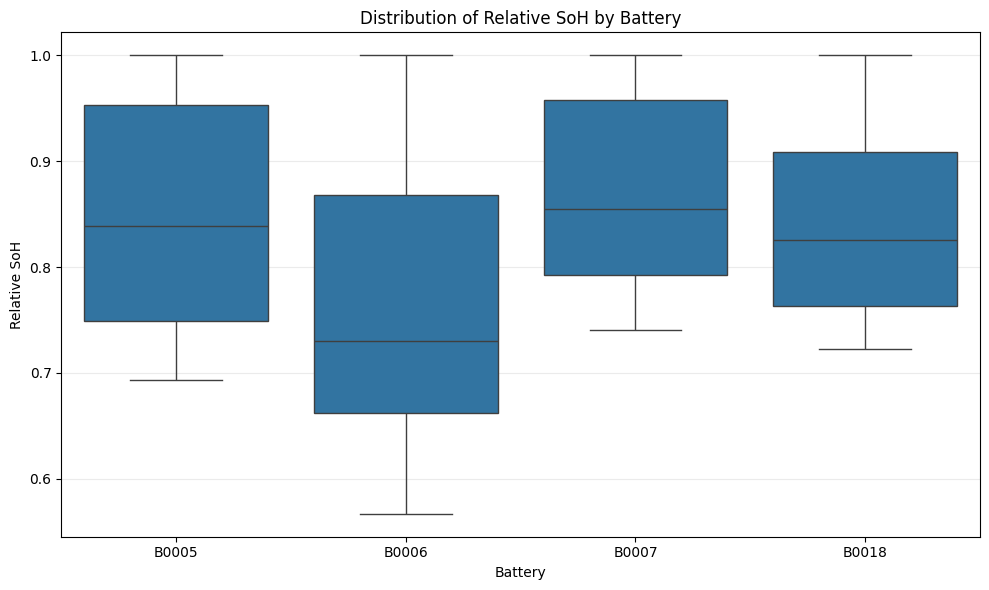

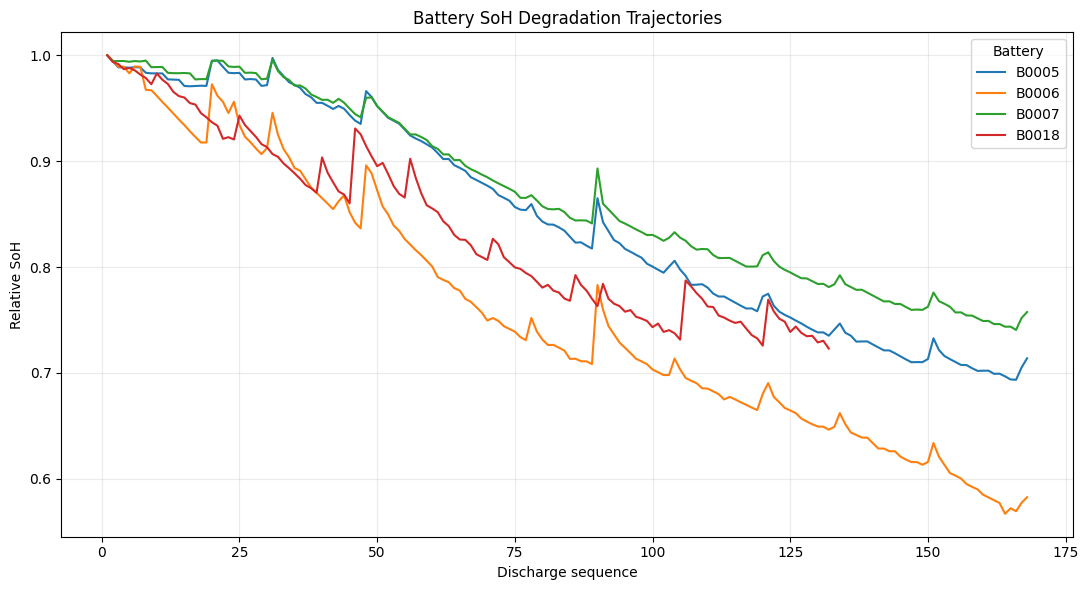

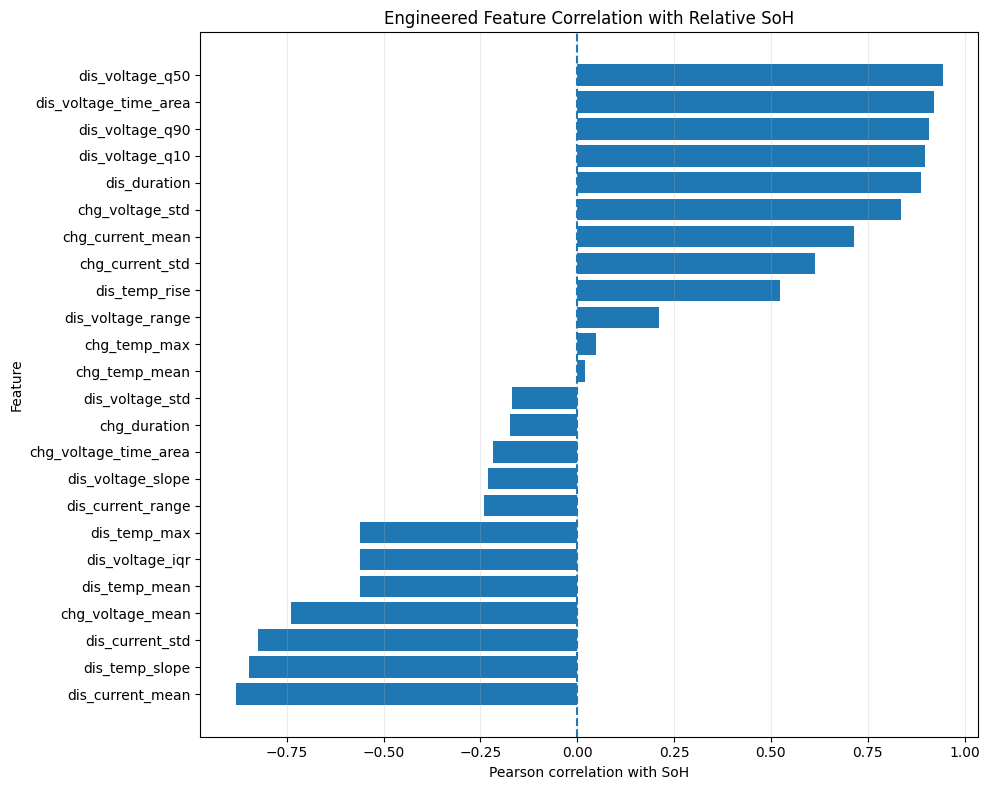

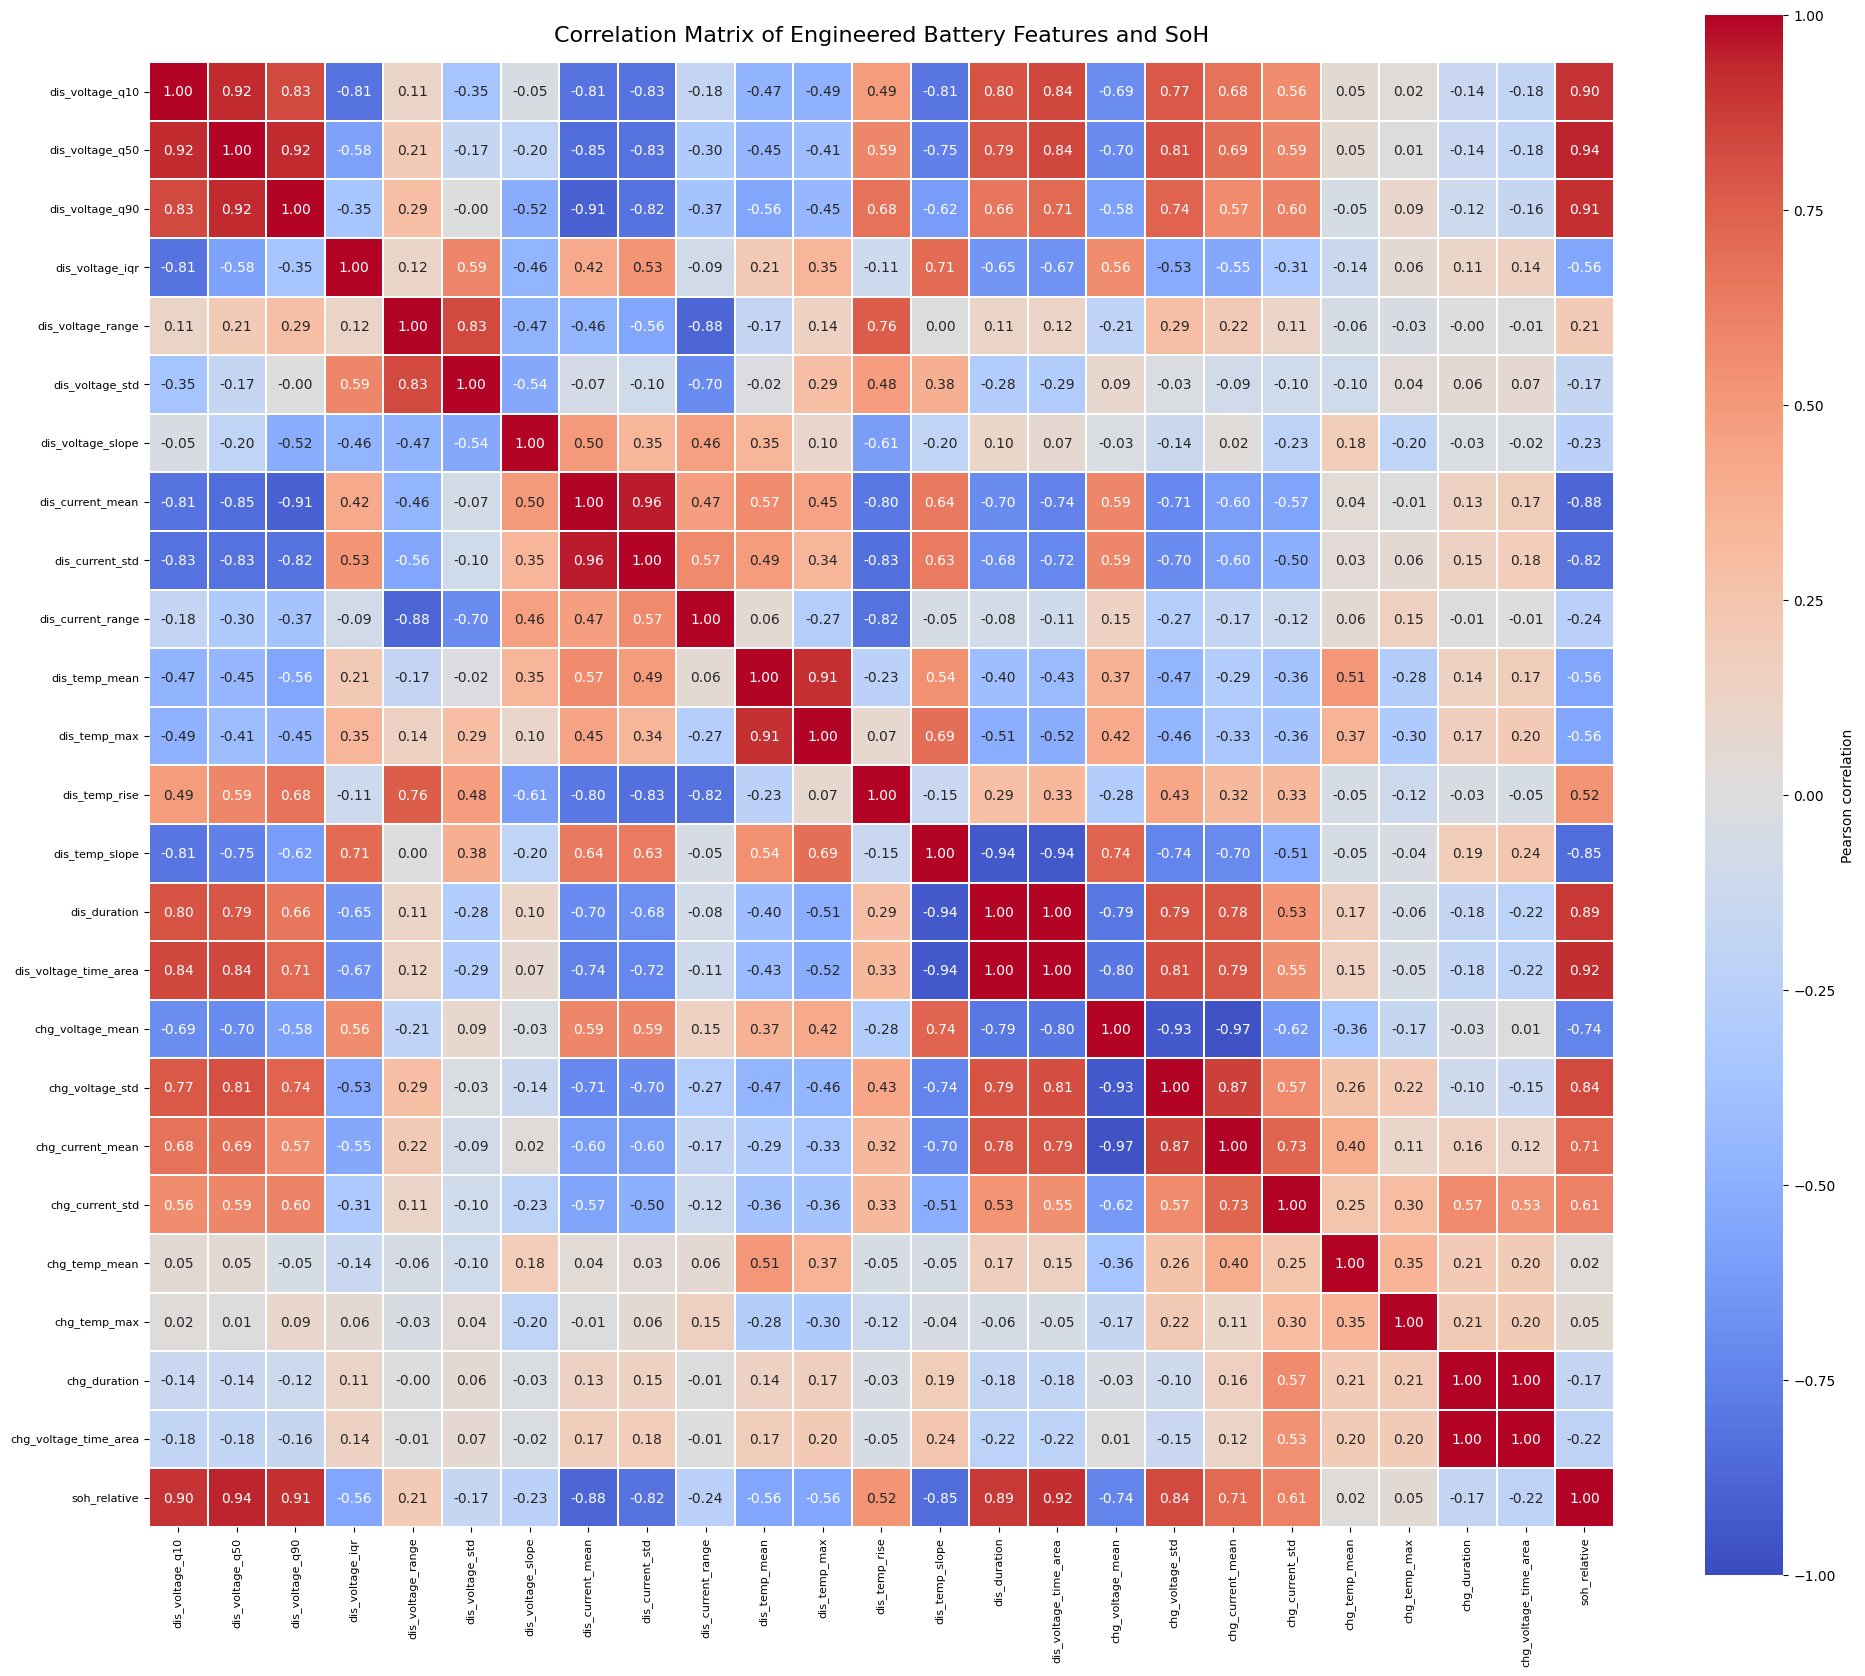

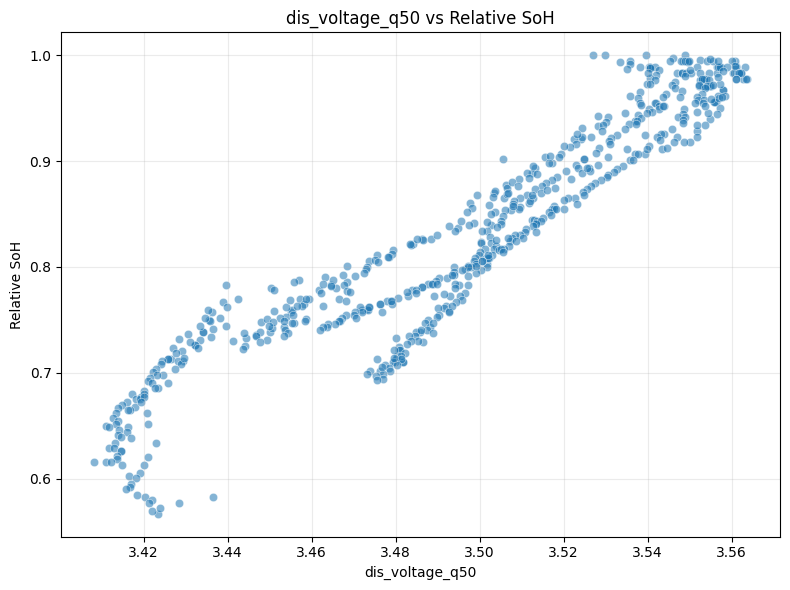

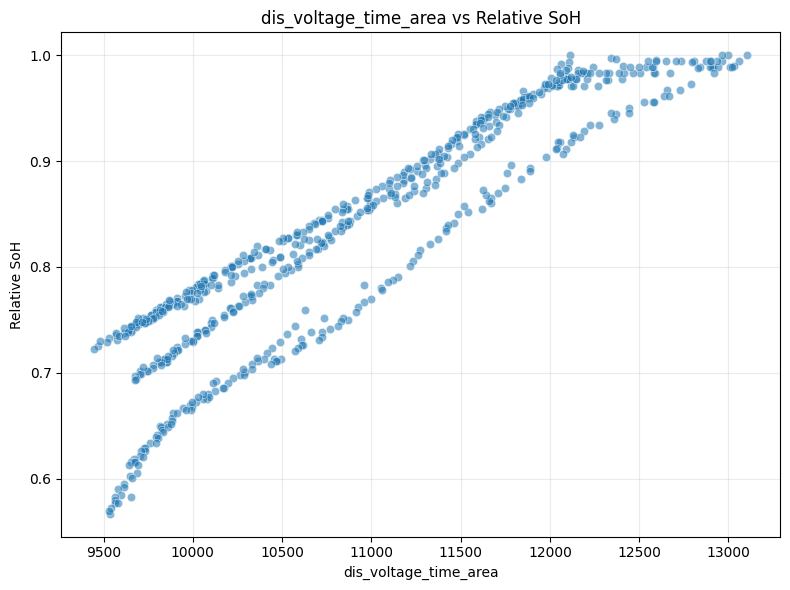

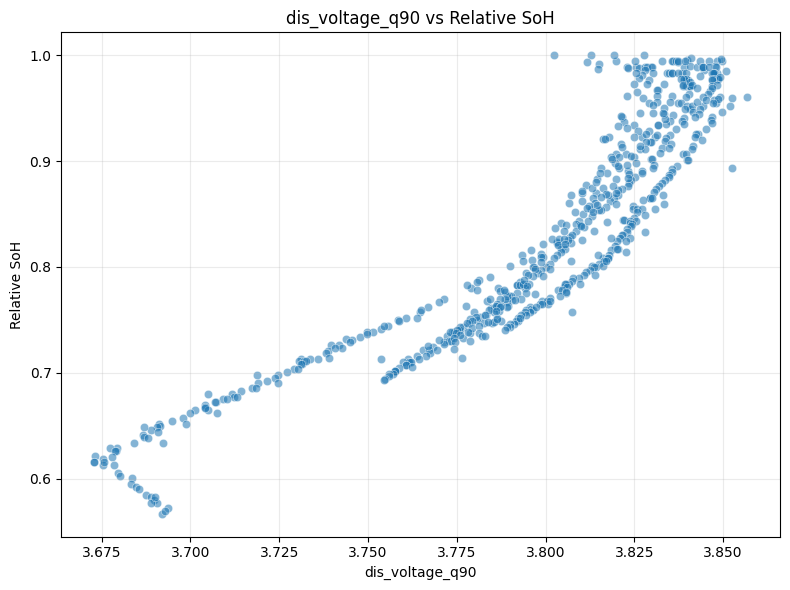

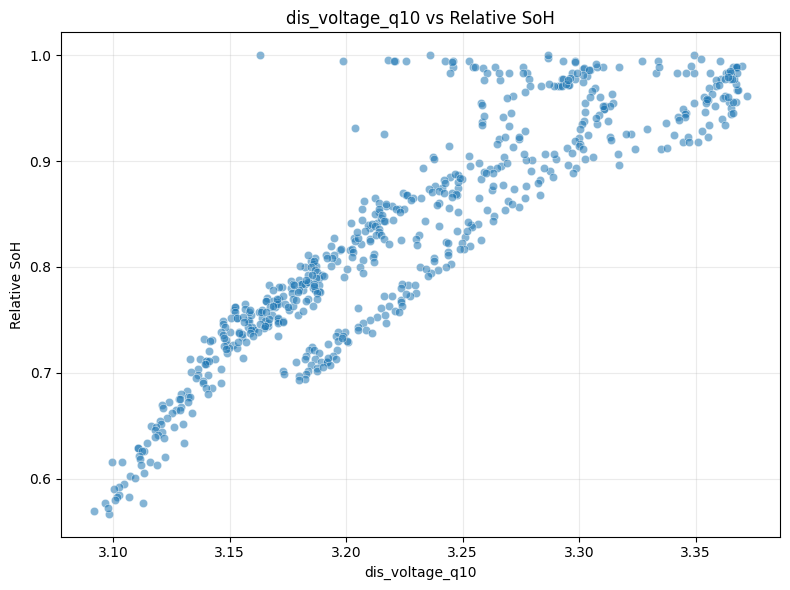

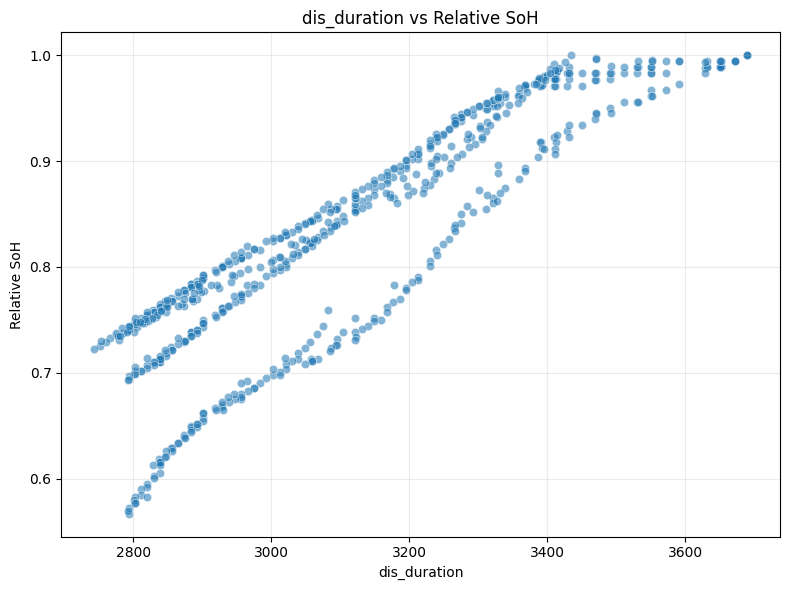

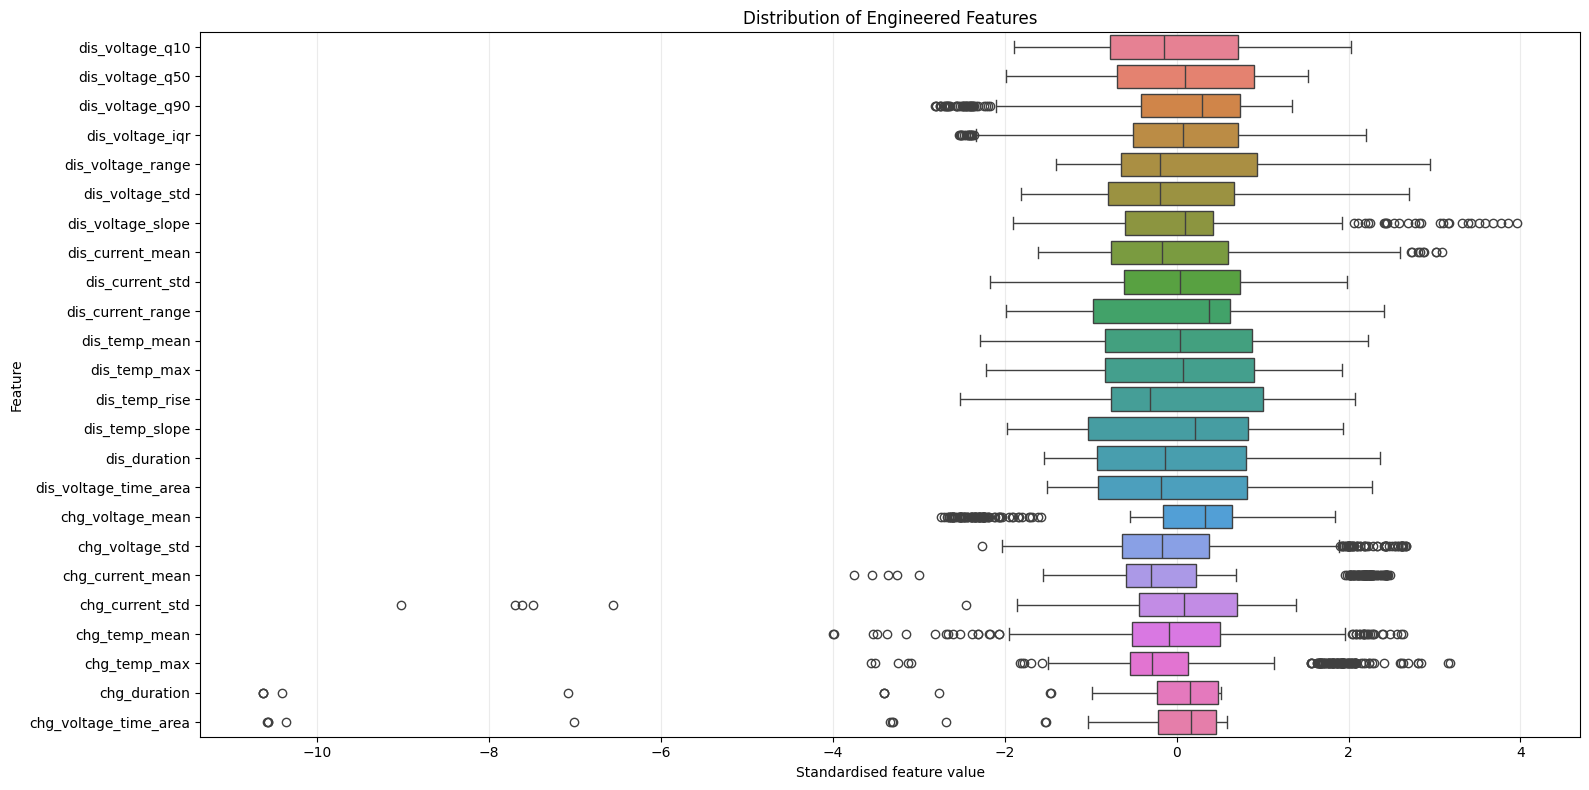

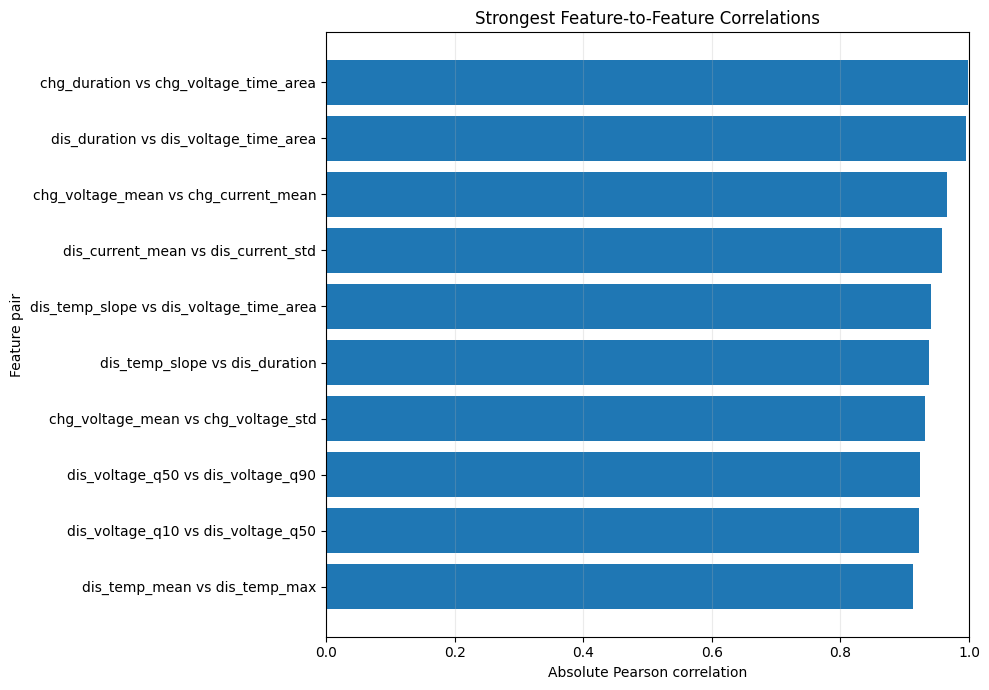

In [3]:
# EDA PLOTS

# 1. SoH distribution by battery

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=feature_data,
    x="battery_id",
    y=TARGET_COLUMN
)

plt.xlabel("Battery")
plt.ylabel("Relative SoH")
plt.title("Distribution of Relative SoH by Battery")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

soh_distribution_file = (
    OUTPUT_DIR / "eda_soh_distribution_by_battery.png"
)

plt.savefig(
    soh_distribution_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 2. SoH degradation trajectory

plt.figure(figsize=(11, 6))

for battery in sorted(feature_data["battery_id"].unique()):

    battery_df = (
        feature_data[
            feature_data["battery_id"] == battery
        ]
        .sort_values("discharge_sequence")
    )

    plt.plot(
        battery_df["discharge_sequence"],
        battery_df[TARGET_COLUMN],
        label=battery
    )

plt.xlabel("Discharge sequence")
plt.ylabel("Relative SoH")
plt.title("Battery SoH Degradation Trajectories")
plt.legend(title="Battery")
plt.grid(alpha=0.25)
plt.tight_layout()

soh_trajectory_file = (
    OUTPUT_DIR / "eda_soh_degradation_trajectories.png"
)

plt.savefig(
    soh_trajectory_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 3. Feature correlation with SoH

plot_corr = feature_soh_correlations.sort_values(
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_corr.index,
    plot_corr.values
)

plt.axvline(0, linestyle="--")
plt.xlabel("Pearson correlation with SoH")
plt.ylabel("Feature")
plt.title("Engineered Feature Correlation with Relative SoH")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

soh_correlation_plot_file = (
    OUTPUT_DIR / "eda_feature_soh_correlations.png"
)

plt.savefig(
    soh_correlation_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 4. Full correlation heatmap

plt.figure(figsize=(20, 17))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.3,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title(
    "Correlation Matrix of Engineered Battery Features and SoH",
    fontsize=16,
    pad=15
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

heatmap_file = (
    OUTPUT_DIR / "feature_correlation_heatmap.png"
)

plt.savefig(
    heatmap_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 5. Top 5 features vs SoH

top_features = (
    feature_soh_correlations
    .abs()
    .sort_values(ascending=False)
    .head(5)
    .index
    .tolist()
)

for feature in top_features:

    plt.figure(figsize=(8, 6))

    sns.scatterplot(
        data=feature_data,
        x=feature,
        y=TARGET_COLUMN,
        alpha=0.55
    )

    plt.xlabel(feature)
    plt.ylabel("Relative SoH")
    plt.title(f"{feature} vs Relative SoH")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    scatter_file = (
        OUTPUT_DIR / f"eda_{safe_name}_vs_soh.png"
    )

    plt.savefig(
        scatter_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# 6. Standardised feature distributions

feature_plot_data = (
    feature_data[candidate_features]
    .copy()
)

feature_plot_data = feature_plot_data.apply(
    lambda column:
    (
        (column - column.mean()) / column.std()
        if column.std() != 0
        else column
    )
)

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=feature_plot_data,
    orient="h"
)

plt.xlabel("Standardised feature value")
plt.ylabel("Feature")
plt.title("Distribution of Engineered Features")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

feature_distribution_file = (
    OUTPUT_DIR / "eda_engineered_feature_distributions.png"
)

plt.savefig(
    feature_distribution_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# 7. Strongest feature-to-feature correlations

CORRELATION_THRESHOLD = 0.90

pairs = []

for i in range(len(candidate_features)):

    for j in range(i + 1, len(candidate_features)):

        feature_a = candidate_features[i]
        feature_b = candidate_features[j]

        correlation = correlation_matrix.loc[
            feature_a,
            feature_b
        ]

        if abs(correlation) >= CORRELATION_THRESHOLD:

            pairs.append({
                "feature_1": feature_a,
                "feature_2": feature_b,
                "correlation": correlation,
                "absolute_correlation": abs(correlation)
            })


if pairs:

    high_corr_pairs = (
        pd.DataFrame(pairs)
        .sort_values(
            "absolute_correlation",
            ascending=False
        )
        .reset_index(drop=True)
    )

else:

    high_corr_pairs = pd.DataFrame(
        columns=[
            "feature_1",
            "feature_2",
            "correlation",
            "absolute_correlation"
        ]
    )


if len(high_corr_pairs) > 0:

    top_pairs = (
        high_corr_pairs
        .head(10)
        .copy()
    )

    top_pairs["pair"] = (
        top_pairs["feature_1"]
        + " vs "
        + top_pairs["feature_2"]
    )

    top_pairs = top_pairs.sort_values(
        "absolute_correlation"
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        top_pairs["pair"],
        top_pairs["absolute_correlation"]
    )

    plt.xlabel("Absolute Pearson correlation")
    plt.ylabel("Feature pair")
    plt.title("Strongest Feature-to-Feature Correlations")
    plt.xlim(0, 1)
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()

    redundancy_plot_file = (
        OUTPUT_DIR / "eda_high_feature_correlations.png"
    )

    plt.savefig(
        redundancy_plot_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

else:

    redundancy_plot_file = None

RANDOM FOREST MODELLING
Dataset rows     : 636
Reduced features : 15
Features         : ['dis_voltage_q50', 'dis_voltage_iqr', 'dis_voltage_range', 'dis_voltage_std', 'dis_voltage_slope', 'dis_current_mean', 'dis_current_range', 'dis_temp_mean', 'dis_temp_rise', 'dis_voltage_time_area', 'chg_voltage_std', 'chg_current_std', 'chg_temp_mean', 'chg_temp_max', 'chg_voltage_time_area']
Batteries        : ['B0005', 'B0006', 'B0007', 'B0018']

DEPTH SANITY CHECK


,max_depth,mean_train_RMSE,mean_validation_RMSE,std_validation_RMSE,mean_validation_MAE,mean_validation_R2,overfit_gap
0,3,0.017325,0.039781,0.022143,0.030374,0.830648,0.022457
1,5,0.009120,0.035197,0.019333,0.027853,0.866021,0.026077
2,8,0.005469,0.035700,0.019852,0.028677,0.861990,0.030231
3,12,0.004856,0.035499,0.019810,0.028565,0.863651,0.030643
4,16,0.004888,0.035304,0.019983,0.028377,0.865261,0.030417
5,20,0.004888,0.035304,0.019983,0.028377,0.865261,0.030417
6,None,0.004888,0.035304,0.019983,0.028377,0.865261,0.030417



Selected max_depth: 5


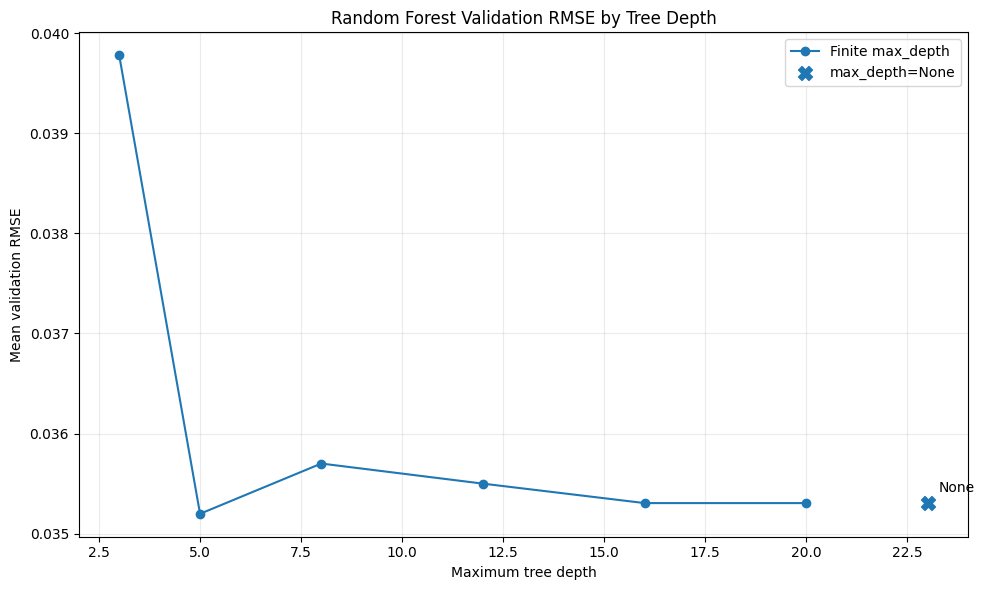


FINAL RANDOM FOREST FEATURE SET
Feature source : automatic_reduced_feature_set.csv
Feature count  : 15
max_depth      : 5
min_samples_leaf: 2
max_features   : sqrt
n_estimators   : 300

RANDOM FOREST BASELINE VS TUNED HOLDOUT


,Model,Evaluation,RMSE,MAE,R2
0,Random Forest,Baseline holdout,0.009906,0.006020,0.991251
1,Random Forest,Tuned holdout,0.012716,0.008724,0.985584



Holdout RMSE improvement: -28.37%

RANDOM FOREST FEATURE IMPORTANCE


,feature,random_forest_importance,rank
0,dis_voltage_q50,0.231322,1
1,dis_voltage_time_area,0.165475,2
2,chg_current_std,0.162378,3
3,chg_voltage_std,0.140450,4
4,dis_current_mean,0.100268,5
5,dis_voltage_slope,0.058438,6
6,dis_voltage_iqr,0.043534,7
7,dis_temp_rise,0.035261,8
8,dis_temp_mean,0.031744,9
9,dis_voltage_std,0.009127,10


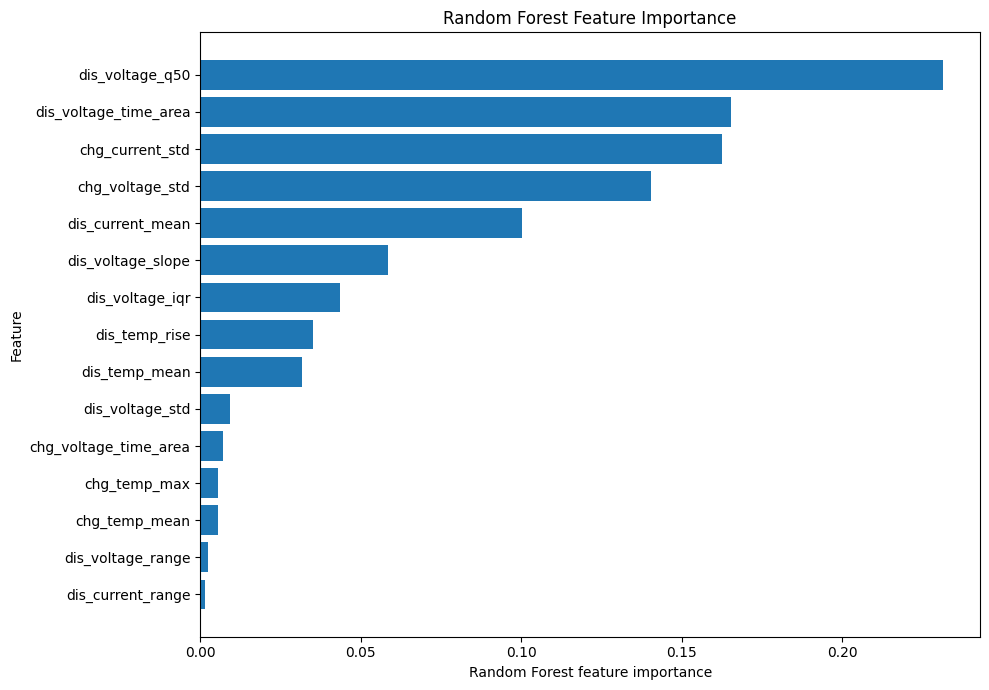


BATTERY-LEVEL LOBO RESULTS


,model,test_battery,train_batteries,train_rows,test_rows,train_RMSE,test_RMSE,test_MAE,test_R2,test_SoH_min,test_SoH_max
0,Baseline Random Forest,B0005,"B0006, B0007, B0018",468,168,0.004370,0.022775,0.016327,0.950398,0.693488,1.0
1,Baseline Random Forest,B0006,"B0005, B0007, B0018",468,168,0.003078,0.063595,0.056345,0.734673,0.566893,1.0
2,Baseline Random Forest,B0007,"B0005, B0006, B0018",468,168,0.004273,0.030385,0.023718,0.871783,0.740569,1.0
3,Baseline Random Forest,B0018,"B0005, B0006, B0007",504,132,0.004269,0.026844,0.019649,0.895844,0.722937,1.0
4,Tuned Random Forest,B0005,"B0006, B0007, B0018",468,168,0.010596,0.019905,0.011432,0.962109,0.693488,1.0
5,Tuned Random Forest,B0006,"B0005, B0007, B0018",468,168,0.006768,0.063520,0.055238,0.735297,0.566893,1.0
6,Tuned Random Forest,B0007,"B0005, B0006, B0018",468,168,0.009677,0.028286,0.022034,0.888891,0.740569,1.0
7,Tuned Random Forest,B0018,"B0005, B0006, B0007",504,132,0.009439,0.029078,0.022707,0.877788,0.722937,1.0



OVERALL LOBO RESULTS


,Model,Evaluation,RMSE,MAE,R2
0,Random Forest,Baseline LOBO,0.039985,0.029540,0.865975
1,Random Forest,Tuned LOBO,0.039463,0.028144,0.869452



RANDOM FOREST — OVERALL COMPARISON


,Model,Evaluation,RMSE,MAE,R2
0,Random Forest,Baseline holdout,0.009906,0.006020,0.991251
1,Random Forest,Tuned holdout,0.012716,0.008724,0.985584
2,Random Forest,Baseline LOBO,0.039985,0.029540,0.865975
3,Random Forest,Tuned LOBO,0.039463,0.028144,0.869452


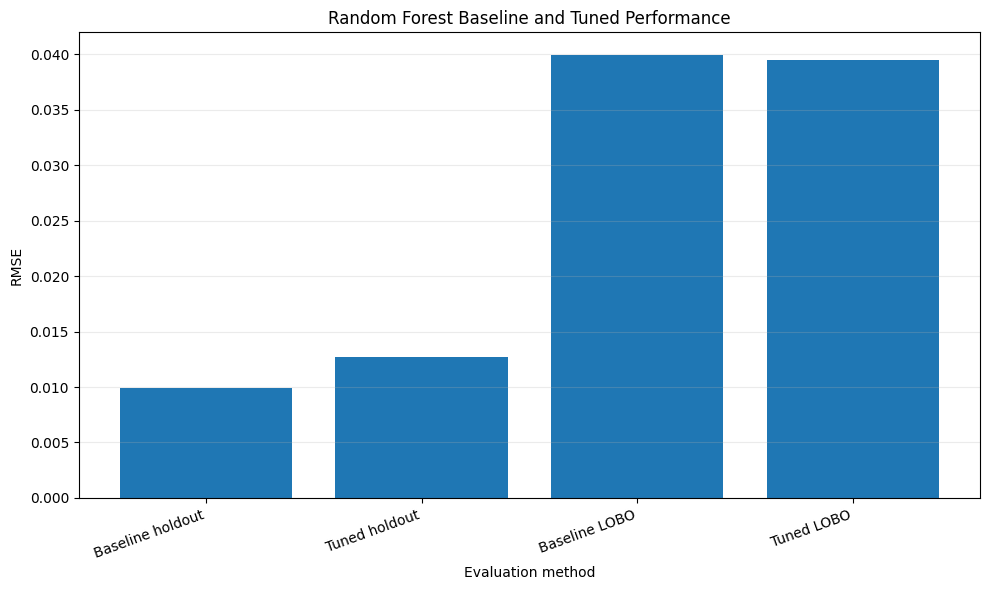

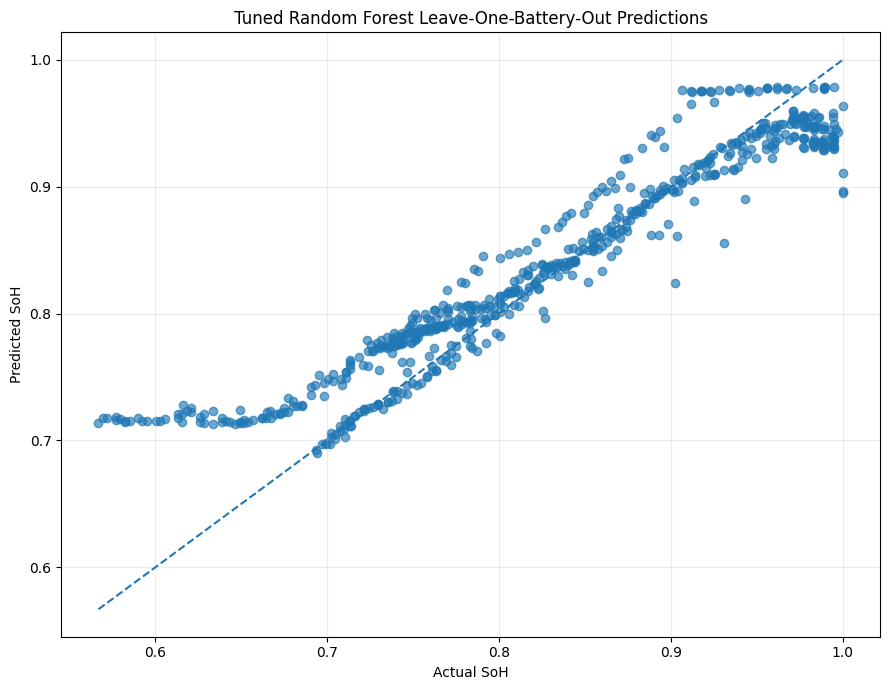

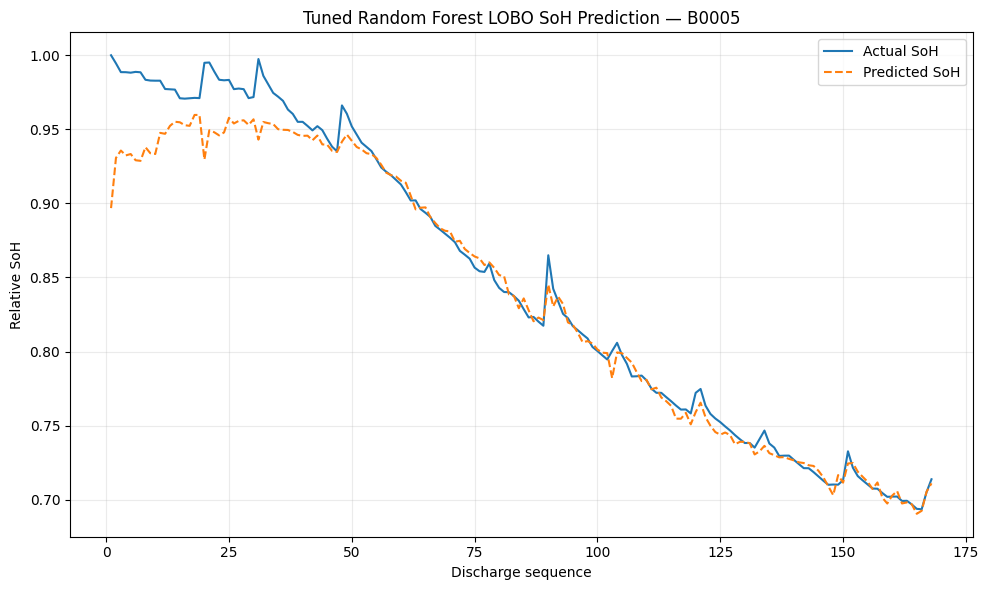

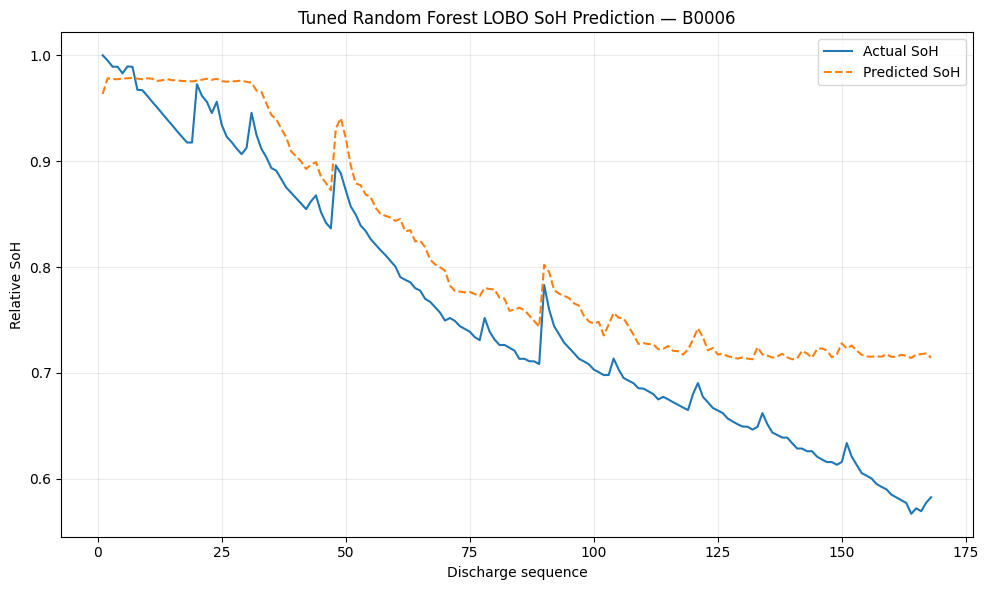

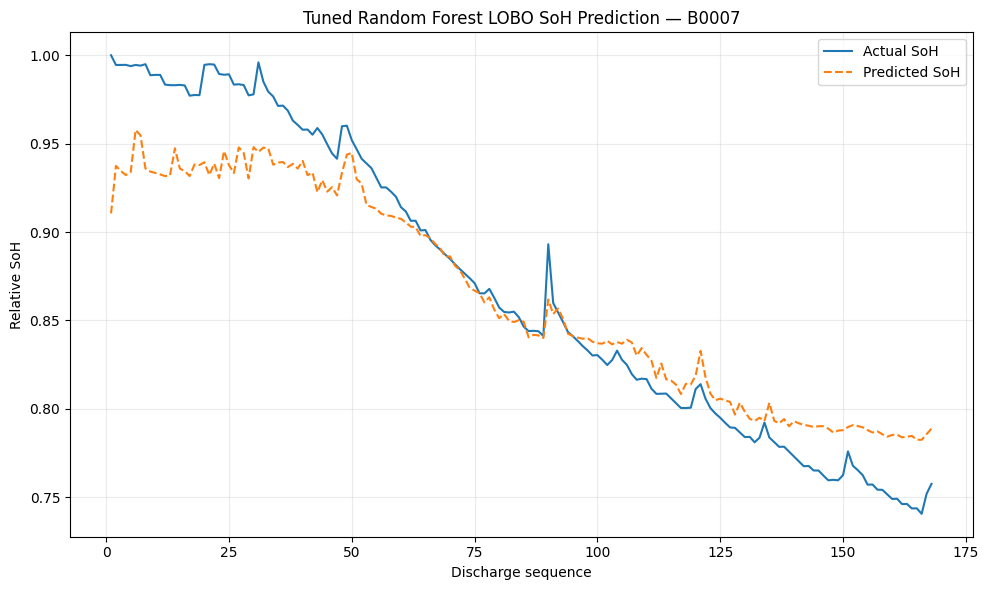

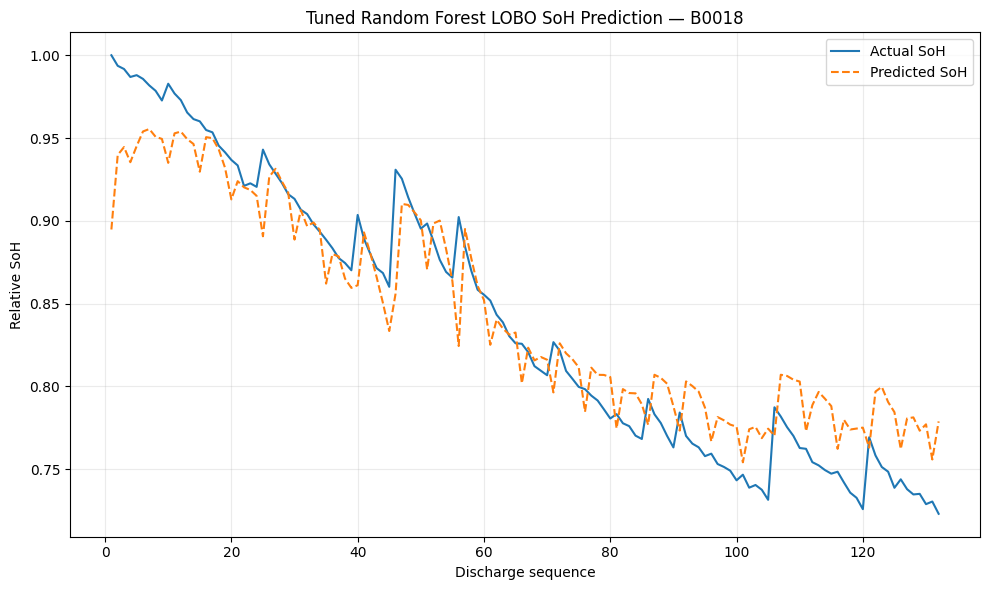

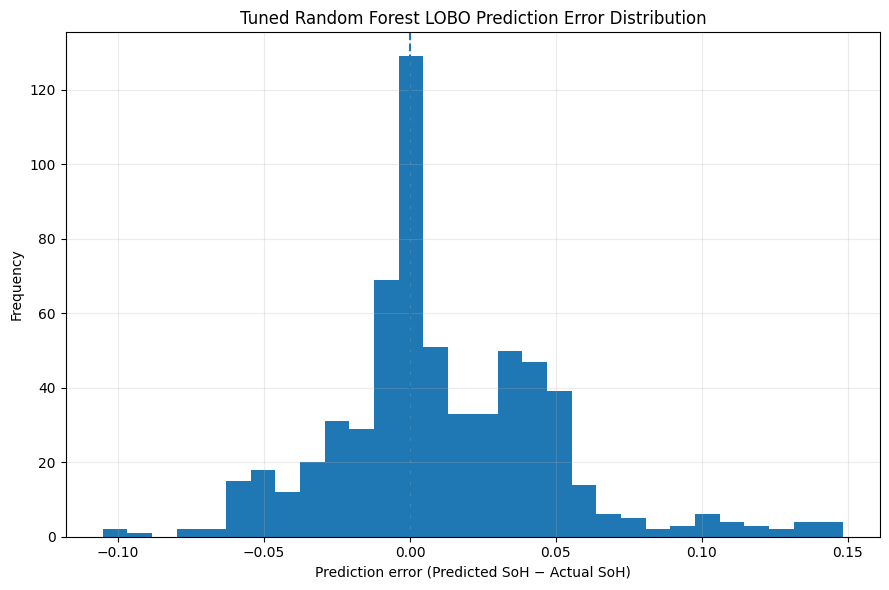


Final Random Forest comparison:


,Model,Evaluation,RMSE,MAE,R2
0,Random Forest,Baseline holdout,0.009906,0.006020,0.991251
1,Random Forest,Tuned holdout,0.012716,0.008724,0.985584
2,Random Forest,Baseline LOBO,0.039985,0.029540,0.865975
3,Random Forest,Tuned LOBO,0.039463,0.028144,0.869452



Main output files:
/content/outputs/random_forest_depth_sanity_check.csv
/content/outputs/random_forest_depth_sanity_check.png
/content/outputs/random_forest_baseline_tuned_holdout.csv
/content/outputs/random_forest_feature_importance.csv
/content/outputs/random_forest_feature_importance.png
/content/outputs/random_forest_final_configuration.csv
/content/outputs/random_forest_baseline_tuned_lobo_metrics.csv
/content/outputs/random_forest_baseline_tuned_lobo_predictions.csv
/content/outputs/random_forest_baseline_tuned_lobo_overall.csv
/content/outputs/random_forest_four_way_comparison.csv
/content/outputs/random_forest_four_way_rmse_comparison.png
/content/outputs/random_forest_lobo_actual_vs_predicted.png
/content/outputs/random_forest_lobo_error_distribution.png


In [7]:
# RANDOM FOREST MODELLING, VALIDATION AND LOBO

RANDOM_STATE = 42
TARGET = "soh_relative"
GROUP = "battery_id"


# Load data

feature_file = OUTPUT_DIR / "battery_soh_feature_dataset.csv"
reduced_file = OUTPUT_DIR / "automatic_reduced_feature_set.csv"

if not feature_file.exists():
    raise FileNotFoundError(
        f"Feature dataset not found: {feature_file}"
    )

if not reduced_file.exists():
    raise FileNotFoundError(
        f"Reduced feature file not found: {reduced_file}"
    )

df = pd.read_csv(feature_file)

selected_features = pd.read_csv(
    reduced_file
)["feature"].tolist()

selected_features = [
    f for f in selected_features
    if f in df.columns
]

groups = df[GROUP]
y = df[TARGET]

cv = GroupKFold(n_splits=4)

print("RANDOM FOREST MODELLING")
print(f"Dataset rows     : {len(df)}")
print(f"Reduced features : {len(selected_features)}")
print(f"Features         : {selected_features}")
print(f"Batteries        : {sorted(df[GROUP].unique())}")


# Helper functions

def metrics(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }


def make_rf(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2
):

    return RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )


def grouped_cv_evaluate(
    features,
    max_depth,
    n_estimators=300,
    min_samples_leaf=2
):

    X = df[features]
    results = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X, y, groups=groups),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_valid = X.iloc[valid_idx]

        y_train = y.iloc[train_idx]
        y_valid = y.iloc[valid_idx]

        model = make_rf(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf
        )

        model.fit(X_train, y_train)

        train_metrics = metrics(
            y_train,
            model.predict(X_train)
        )

        valid_metrics = metrics(
            y_valid,
            model.predict(X_valid)
        )

        results.append({
            "fold": fold,
            "train_RMSE": train_metrics["RMSE"],
            "validation_RMSE": valid_metrics["RMSE"],
            "validation_MAE": valid_metrics["MAE"],
            "validation_R2": valid_metrics["R2"]
        })

    return pd.DataFrame(results)


# Random Forest depth sanity check

depth_values = [3, 5, 8, 12, 16, 20, None]

depth_results = []

for depth in depth_values:

    fold_df = grouped_cv_evaluate(
        selected_features,
        max_depth=depth
    )

    depth_results.append({
        "max_depth":
            "None" if depth is None else str(depth),

        "mean_train_RMSE":
            fold_df["train_RMSE"].mean(),

        "mean_validation_RMSE":
            fold_df["validation_RMSE"].mean(),

        "std_validation_RMSE":
            fold_df["validation_RMSE"].std(),

        "mean_validation_MAE":
            fold_df["validation_MAE"].mean(),

        "mean_validation_R2":
            fold_df["validation_R2"].mean()
    })


depth_results_df = pd.DataFrame(depth_results)

depth_results_df["depth_numeric"] = (
    depth_results_df["max_depth"]
    .replace("None", np.nan)
    .astype(float)
)

depth_results_df = (
    depth_results_df
    .sort_values(
        "depth_numeric",
        na_position="last"
    )
    .drop(columns="depth_numeric")
    .reset_index(drop=True)
)

depth_results_df["overfit_gap"] = (
    depth_results_df["mean_validation_RMSE"]
    -
    depth_results_df["mean_train_RMSE"]
)


best_depth_row = depth_results_df.loc[
    depth_results_df["mean_validation_RMSE"].idxmin()
]

best_depth_label = best_depth_row["max_depth"]

selected_depth = (
    None
    if best_depth_label == "None"
    else int(best_depth_label)
)


print("\nDEPTH SANITY CHECK")
display(depth_results_df.round(6))

print(f"\nSelected max_depth: {selected_depth}")


# Save depth results

depth_file = (
    OUTPUT_DIR
    / "random_forest_depth_sanity_check.csv"
)

depth_results_df.to_csv(
    depth_file,
    index=False
)


# Depth plot

finite = depth_results_df[
    depth_results_df["max_depth"] != "None"
]

unrestricted = depth_results_df[
    depth_results_df["max_depth"] == "None"
]

plt.figure(figsize=(10, 6))

plt.plot(
    finite["max_depth"].astype(int),
    finite["mean_validation_RMSE"],
    marker="o",
    label="Finite max_depth"
)

if len(unrestricted) == 1:

    x_none = (
        finite["max_depth"].astype(int).max() + 3
    )

    y_none = unrestricted[
        "mean_validation_RMSE"
    ].iloc[0]

    plt.scatter(
        x_none,
        y_none,
        marker="X",
        s=100,
        label="max_depth=None"
    )

    plt.annotate(
        "None",
        (x_none, y_none),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.xlabel("Maximum tree depth")
plt.ylabel("Mean validation RMSE")
plt.title("Random Forest Validation RMSE by Tree Depth")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

depth_plot_file = (
    OUTPUT_DIR
    / "random_forest_depth_sanity_check.png"
)

plt.savefig(
    depth_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Final Random Forest feature set

print("\nFINAL RANDOM FOREST FEATURE SET")
print(f"Feature source : automatic_reduced_feature_set.csv")
print(f"Feature count  : {len(selected_features)}")
print(f"max_depth      : {selected_depth}")
print("min_samples_leaf: 2")
print("max_features   : sqrt")
print("n_estimators   : 300")


# Baseline vs tuned 80/20 holdout

X = df[selected_features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)


holdout_configs = {

    "Baseline holdout": {
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 1
    },

    "Tuned holdout": {
        "n_estimators": 300,
        "max_depth": selected_depth,
        "min_samples_leaf": 2
    }
}


holdout_results = []

for evaluation, config in holdout_configs.items():

    model = make_rf(**config)

    model.fit(
        X_train,
        y_train
    )

    result = metrics(
        y_test,
        model.predict(X_test)
    )

    holdout_results.append({
        "Model": "Random Forest",
        "Evaluation": evaluation,
        "RMSE": result["RMSE"],
        "MAE": result["MAE"],
        "R2": result["R2"]
    })


rf_holdout_comparison = pd.DataFrame(
    holdout_results
)


rf_holdout_file = (
    OUTPUT_DIR
    / "random_forest_baseline_tuned_holdout.csv"
)

rf_holdout_comparison.to_csv(
    rf_holdout_file,
    index=False
)


print("\nRANDOM FOREST BASELINE VS TUNED HOLDOUT")
display(
    rf_holdout_comparison.round(6)
)


baseline_rmse = (
    rf_holdout_comparison.loc[
        rf_holdout_comparison["Evaluation"]
        == "Baseline holdout",
        "RMSE"
    ].iloc[0]
)

tuned_rmse = (
    rf_holdout_comparison.loc[
        rf_holdout_comparison["Evaluation"]
        == "Tuned holdout",
        "RMSE"
    ].iloc[0]
)

print(
    f"\nHoldout RMSE improvement: "
    f"{(baseline_rmse - tuned_rmse) / baseline_rmse * 100:.2f}%"
)


# Final Random Forest feature importance

final_rf = make_rf(
    n_estimators=300,
    max_depth=selected_depth,
    min_samples_leaf=2
)

final_rf.fit(
    df[selected_features],
    y
)


importance_df = pd.DataFrame({
    "feature": selected_features,
    "random_forest_importance":
        final_rf.feature_importances_
}).sort_values(
    "random_forest_importance",
    ascending=False
).reset_index(drop=True)

importance_df["rank"] = (
    np.arange(1, len(importance_df) + 1)
)


importance_file = (
    OUTPUT_DIR
    / "random_forest_feature_importance.csv"
)

importance_df.to_csv(
    importance_file,
    index=False
)


print("\nRANDOM FOREST FEATURE IMPORTANCE")
display(
    importance_df.round(6)
)


top_importance = (
    importance_df
    .head(15)
    .sort_values(
        "random_forest_importance"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_importance["feature"],
    top_importance["random_forest_importance"]
)

plt.xlabel("Random Forest feature importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()

importance_plot_file = (
    OUTPUT_DIR
    / "random_forest_feature_importance.png"
)

plt.savefig(
    importance_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Save final configuration

configuration = pd.DataFrame({

    "parameter": [
        "feature_source",
        "feature_count",
        "n_estimators",
        "max_depth",
        "min_samples_leaf",
        "max_features",
        "random_state"
    ],

    "value": [
        "automatic_reduced_feature_set.csv",
        len(selected_features),
        300,
        str(selected_depth),
        2,
        "sqrt",
        RANDOM_STATE
    ]
})


configuration_file = (
    OUTPUT_DIR
    / "random_forest_final_configuration.csv"
)

configuration.to_csv(
    configuration_file,
    index=False
)


# Leave-one-battery-out (LOBO)

batteries = sorted(
    df[GROUP].unique()
)


n_estimators = 300
min_samples_leaf = 2


lobo_configs = {

    "Baseline Random Forest": {
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 1
    },

    "Tuned Random Forest": {
        "n_estimators": n_estimators,
        "max_depth": selected_depth,
        "min_samples_leaf": min_samples_leaf
    }
}


lobo_metrics = []
lobo_predictions = []


for model_name, config in lobo_configs.items():

    for test_battery in batteries:

        train_df = df[
            df[GROUP] != test_battery
        ]

        test_df = df[
            df[GROUP] == test_battery
        ]

        model = make_rf(**config)

        model.fit(
            train_df[selected_features],
            train_df[TARGET]
        )

        train_pred = model.predict(
            train_df[selected_features]
        )

        test_pred = model.predict(
            test_df[selected_features]
        )

        test_metrics = metrics(
            test_df[TARGET],
            test_pred
        )

        train_rmse = np.sqrt(
            mean_squared_error(
                train_df[TARGET],
                train_pred
            )
        )

        lobo_metrics.append({

            "model":
                model_name,

            "test_battery":
                test_battery,

            "train_batteries":
                ", ".join(
                    b for b in batteries
                    if b != test_battery
                ),

            "train_rows":
                len(train_df),

            "test_rows":
                len(test_df),

            "train_RMSE":
                train_rmse,

            "test_RMSE":
                test_metrics["RMSE"],

            "test_MAE":
                test_metrics["MAE"],

            "test_R2":
                test_metrics["R2"],

            "test_SoH_min":
                test_df[TARGET].min(),

            "test_SoH_max":
                test_df[TARGET].max()
        })


        prediction_frame = pd.DataFrame({

            "model":
                model_name,

            "battery_id":
                test_battery,

            "cycle_number":
                test_df["cycle_number"].to_numpy(),

            "discharge_sequence":
                test_df["discharge_sequence"].to_numpy(),

            "actual_soh":
                test_df[TARGET].to_numpy(),

            "predicted_soh":
                test_pred
        })

        prediction_frame["prediction_error"] = (
            prediction_frame["predicted_soh"]
            -
            prediction_frame["actual_soh"]
        )

        prediction_frame["absolute_error"] = (
            prediction_frame["prediction_error"].abs()
        )

        lobo_predictions.append(
            prediction_frame
        )


lobo_metrics_df = pd.DataFrame(
    lobo_metrics
)

lobo_predictions_df = pd.concat(
    lobo_predictions,
    ignore_index=True
)


print("\nBATTERY-LEVEL LOBO RESULTS")
display(
    lobo_metrics_df.round(6)
)


# Overall LOBO results

overall_lobo_results = []

for model_name, evaluation in [

    (
        "Baseline Random Forest",
        "Baseline LOBO"
    ),

    (
        "Tuned Random Forest",
        "Tuned LOBO"
    )

]:

    result_df = lobo_predictions_df[
        lobo_predictions_df["model"]
        == model_name
    ]

    result = metrics(
        result_df["actual_soh"],
        result_df["predicted_soh"]
    )

    overall_lobo_results.append({

        "Model":
            "Random Forest",

        "Evaluation":
            evaluation,

        "RMSE":
            result["RMSE"],

        "MAE":
            result["MAE"],

        "R2":
            result["R2"]
    })


overall_lobo_df = pd.DataFrame(
    overall_lobo_results
)


print("\nOVERALL LOBO RESULTS")
display(
    overall_lobo_df.round(6)
)


# Save LOBO outputs

lobo_metrics_file = (
    OUTPUT_DIR
    / "random_forest_baseline_tuned_lobo_metrics.csv"
)

lobo_predictions_file = (
    OUTPUT_DIR
    / "random_forest_baseline_tuned_lobo_predictions.csv"
)

overall_lobo_file = (
    OUTPUT_DIR
    / "random_forest_baseline_tuned_lobo_overall.csv"
)

lobo_metrics_df.to_csv(
    lobo_metrics_file,
    index=False
)

lobo_predictions_df.to_csv(
    lobo_predictions_file,
    index=False
)

overall_lobo_df.to_csv(
    overall_lobo_file,
    index=False
)


# Four-way comparison

four_way_comparison = pd.concat(
    [
        rf_holdout_comparison,
        overall_lobo_df
    ],
    ignore_index=True
)

evaluation_order = [
    "Baseline holdout",
    "Tuned holdout",
    "Baseline LOBO",
    "Tuned LOBO"
]

four_way_comparison["Evaluation"] = pd.Categorical(
    four_way_comparison["Evaluation"],
    categories=evaluation_order,
    ordered=True
)

four_way_comparison = (
    four_way_comparison
    .sort_values("Evaluation")
    .reset_index(drop=True)
)


four_way_file = (
    OUTPUT_DIR
    / "random_forest_four_way_comparison.csv"
)

four_way_comparison.to_csv(
    four_way_file,
    index=False
)


print("\nRANDOM FOREST — OVERALL COMPARISON")
display(
    four_way_comparison.round(6)
)


# Four-way RMSE plot

plt.figure(figsize=(10, 6))

plt.bar(
    four_way_comparison["Evaluation"],
    four_way_comparison["RMSE"]
)

plt.xlabel("Evaluation method")
plt.ylabel("RMSE")
plt.title("Random Forest Baseline and Tuned Performance")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

four_way_plot_file = (
    OUTPUT_DIR
    / "random_forest_four_way_rmse_comparison.png"
)

plt.savefig(
    four_way_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Tuned LOBO diagnostic plots

tuned_predictions = lobo_predictions_df[
    lobo_predictions_df["model"]
    == "Tuned Random Forest"
]


# Actual vs predicted

plt.figure(figsize=(9, 7))

plt.scatter(
    tuned_predictions["actual_soh"],
    tuned_predictions["predicted_soh"],
    alpha=0.65
)

min_value = min(
    tuned_predictions["actual_soh"].min(),
    tuned_predictions["predicted_soh"].min()
)

max_value = max(
    tuned_predictions["actual_soh"].max(),
    tuned_predictions["predicted_soh"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")
plt.title(
    "Tuned Random Forest "
    "Leave-One-Battery-Out Predictions"
)
plt.grid(alpha=0.25)
plt.tight_layout()

scatter_file = (
    OUTPUT_DIR
    / "random_forest_lobo_actual_vs_predicted.png"
)

plt.savefig(
    scatter_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Actual vs predicted for each battery

for battery in batteries:

    battery_results = (
        tuned_predictions[
            tuned_predictions["battery_id"] == battery
        ]
        .sort_values("discharge_sequence")
    )

    plt.figure(figsize=(10, 6))

    plt.plot(
        battery_results["discharge_sequence"],
        battery_results["actual_soh"],
        label="Actual SoH"
    )

    plt.plot(
        battery_results["discharge_sequence"],
        battery_results["predicted_soh"],
        linestyle="--",
        label="Predicted SoH"
    )

    plt.xlabel("Discharge sequence")
    plt.ylabel("Relative SoH")

    plt.title(
        f"Tuned Random Forest LOBO "
        f"SoH Prediction — {battery}"
    )

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR
        / f"random_forest_lobo_{battery}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# Prediction error distribution

plt.figure(figsize=(9, 6))

plt.hist(
    tuned_predictions["prediction_error"],
    bins=30
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction error "
    "(Predicted SoH − Actual SoH)"
)

plt.ylabel("Frequency")

plt.title(
    "Tuned Random Forest "
    "LOBO Prediction Error Distribution"
)

plt.grid(alpha=0.25)
plt.tight_layout()

error_plot_file = (
    OUTPUT_DIR
    / "random_forest_lobo_error_distribution.png"
)

plt.savefig(
    error_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Final summary

print("\nFinal Random Forest comparison:")
display(
    four_way_comparison.round(6)
)

print("\nMain output files:")

for file in [
    depth_file,
    depth_plot_file,
    rf_holdout_file,
    importance_file,
    importance_plot_file,
    configuration_file,
    lobo_metrics_file,
    lobo_predictions_file,
    overall_lobo_file,
    four_way_file,
    four_way_plot_file,
    scatter_file,
    error_plot_file
]:

    print(file)

XGBOOST MODELLING
Dataset rows       : 636
Reduced features   : 15
Batteries          : ['B0005', 'B0006', 'B0007', 'B0018']

Selected features:
['dis_voltage_q50', 'dis_voltage_iqr', 'dis_voltage_range', 'dis_voltage_std', 'dis_voltage_slope', 'dis_current_mean', 'dis_current_range', 'dis_temp_mean', 'dis_temp_rise', 'dis_voltage_time_area', 'chg_voltage_std', 'chg_current_std', 'chg_temp_mean', 'chg_temp_max', 'chg_voltage_time_area']

Baseline XGBoost:
{'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.1, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 1, 'reg_alpha': 0, 'reg_lambda': 1, 'objective': 'reg:squarederror', 'eval_metric': 'rmse'}

Tuned XGBoost:
{'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 3, 'reg_alpha': 0, 'reg_lambda': 1, 'objective': 'reg:squarederror', 'eval_metric': 'rmse'}

XGBOOST BASELINE VS TUNED HOLDOUT


,Model,Evaluation,MAE,RMSE,R2
0,XGBoost,Baseline holdout,0.005305,0.007495,0.994992
1,XGBoost,Tuned holdout,0.004289,0.006309,0.996452



HOLDOUT IMPROVEMENT
RMSE improvement: 15.82%
MAE improvement: 19.14%

Baseline XGBoost
----------------
B0005: RMSE=0.025658, MAE=0.021268, R²=0.937045
B0006: RMSE=0.062958, MAE=0.058265, R²=0.739961
B0007: RMSE=0.031680, MAE=0.027229, R²=0.860629
B0018: RMSE=0.029407, MAE=0.024246, R²=0.875008

Tuned XGBoost
-------------
B0005: RMSE=0.013651, MAE=0.011450, R²=0.982181
B0006: RMSE=0.060994, MAE=0.055910, R²=0.755934
B0007: RMSE=0.029939, MAE=0.026444, R²=0.875525
B0018: RMSE=0.029563, MAE=0.024402, R²=0.873676

BATTERY-LEVEL XGBOOST LOBO RESULTS


,model,test_battery,train_batteries,train_rows,test_rows,train_RMSE,test_RMSE,test_MAE,test_R2,test_SoH_min,test_SoH_max
0,Baseline XGBoost,B0005,"B0006, B0007, B0018",468,168,0.000634,0.025658,0.021268,0.937045,0.693488,1.0
1,Baseline XGBoost,B0006,"B0005, B0007, B0018",468,168,0.000524,0.062958,0.058265,0.739961,0.566893,1.0
2,Baseline XGBoost,B0007,"B0005, B0006, B0018",468,168,0.000609,0.031680,0.027229,0.860629,0.740569,1.0
3,Baseline XGBoost,B0018,"B0005, B0006, B0007",504,132,0.000665,0.029407,0.024246,0.875008,0.722937,1.0
4,Tuned XGBoost,B0005,"B0006, B0007, B0018",468,168,0.002029,0.013651,0.011450,0.982181,0.693488,1.0
5,Tuned XGBoost,B0006,"B0005, B0007, B0018",468,168,0.001149,0.060994,0.055910,0.755934,0.566893,1.0
6,Tuned XGBoost,B0007,"B0005, B0006, B0018",468,168,0.002115,0.029939,0.026444,0.875525,0.740569,1.0
7,Tuned XGBoost,B0018,"B0005, B0006, B0007",504,132,0.001921,0.029563,0.024402,0.873676,0.722937,1.0



OVERALL XGBOOST LOBO RESULTS


,Model,Evaluation,MAE,RMSE,R2
0,XGBoost,Baseline LOBO,0.033233,0.040811,0.860382
1,XGBoost,Tuned LOBO,0.029843,0.038080,0.878439



BASELINE VS TUNED XGBOOST LOBO
Baseline LOBO RMSE: 0.040811
Tuned LOBO RMSE: 0.038080
RMSE improvement: 6.69%
MAE improvement: 10.20%

XGBOOST — OVERALL COMPARISON


,Model,Evaluation,MAE,RMSE,R2
0,XGBoost,Baseline holdout,0.005305,0.007495,0.994992
1,XGBoost,Tuned holdout,0.004289,0.006309,0.996452
2,XGBoost,Baseline LOBO,0.033233,0.040811,0.860382
3,XGBoost,Tuned LOBO,0.029843,0.038080,0.878439


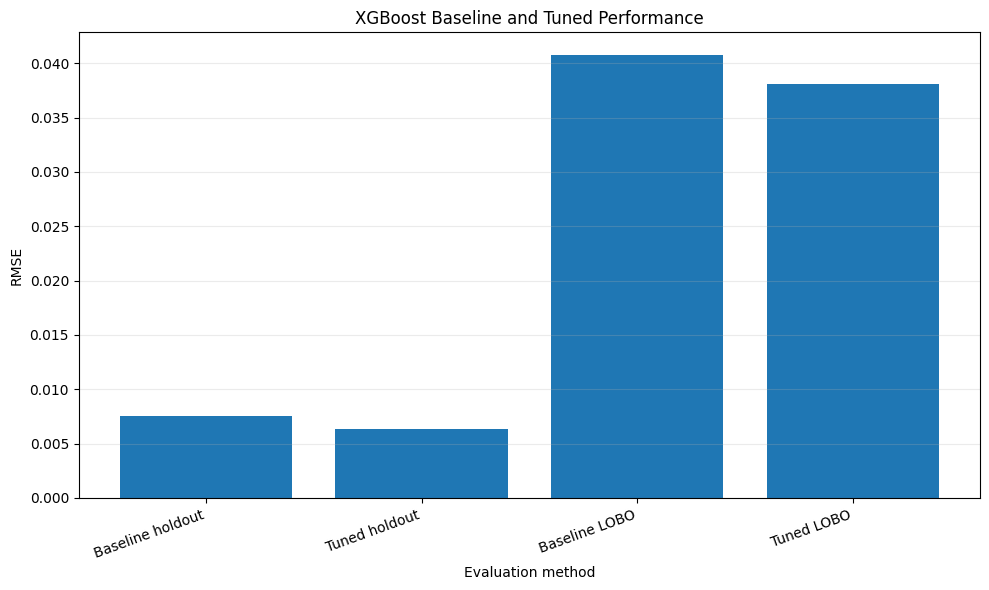

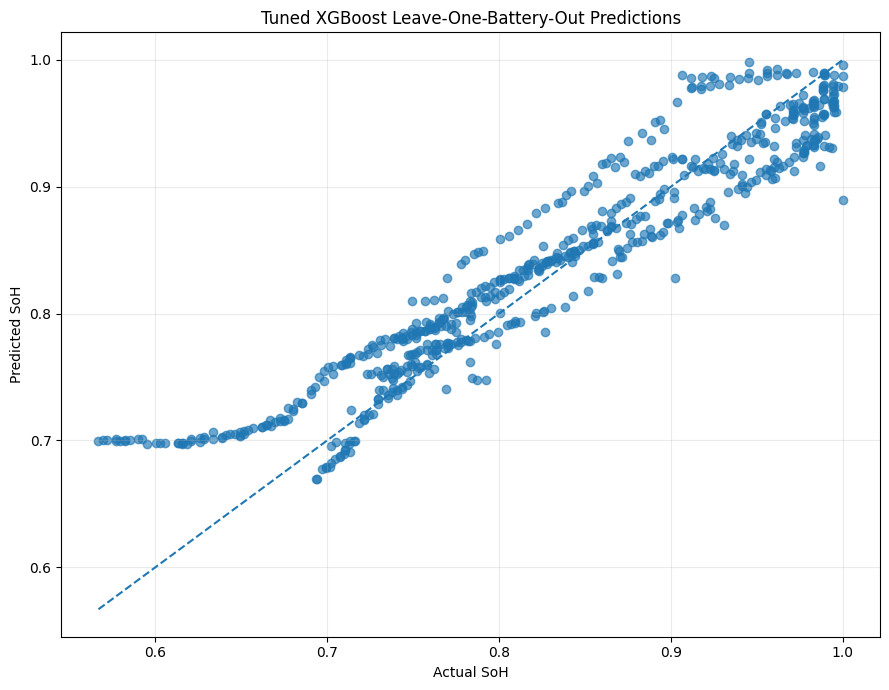

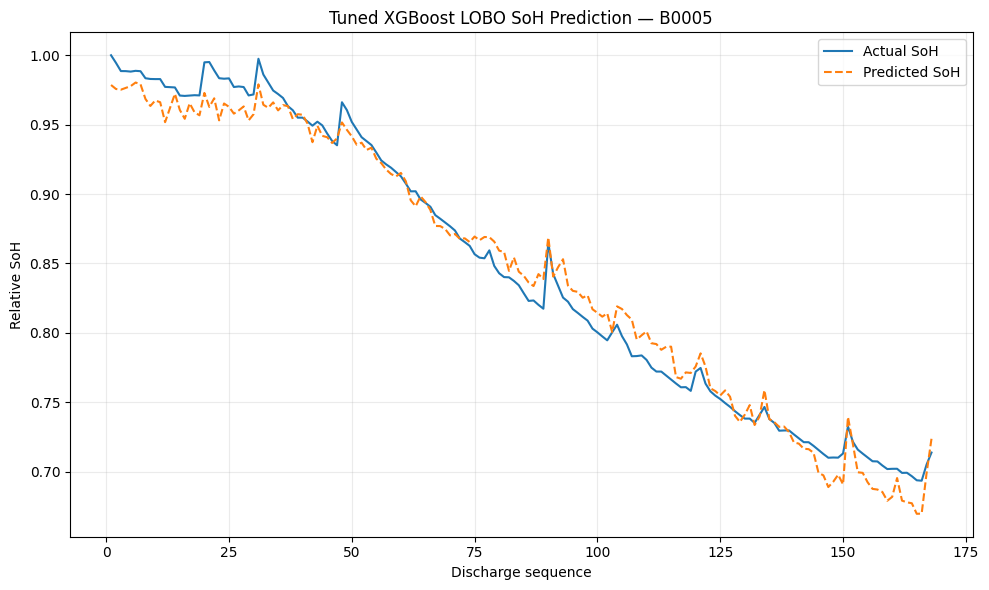

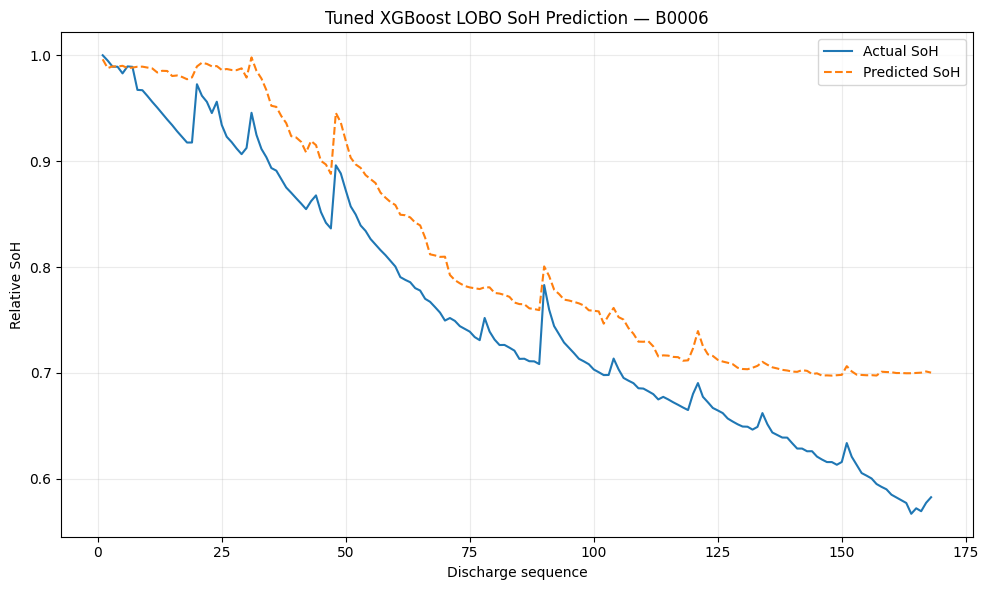

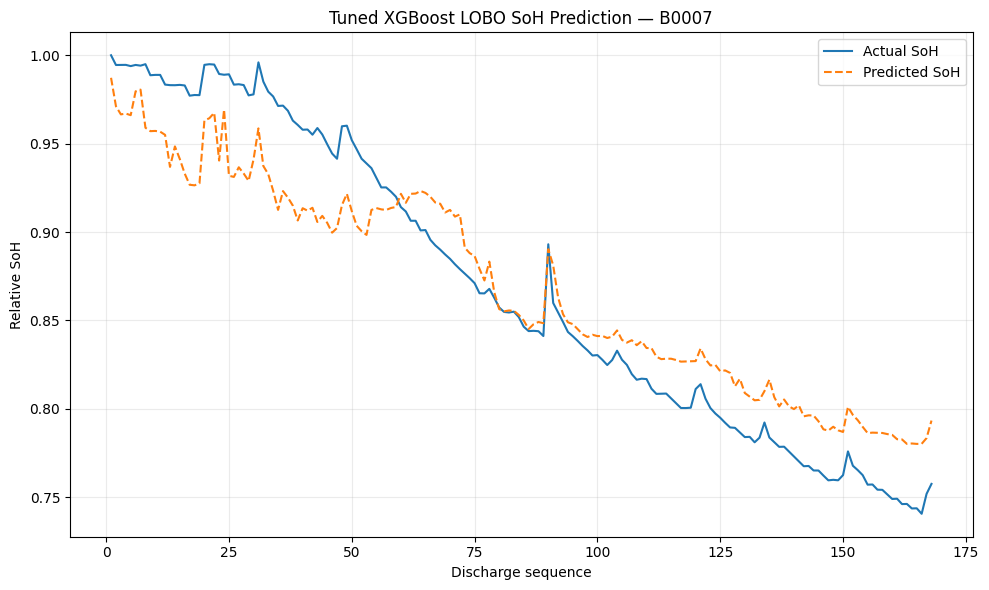

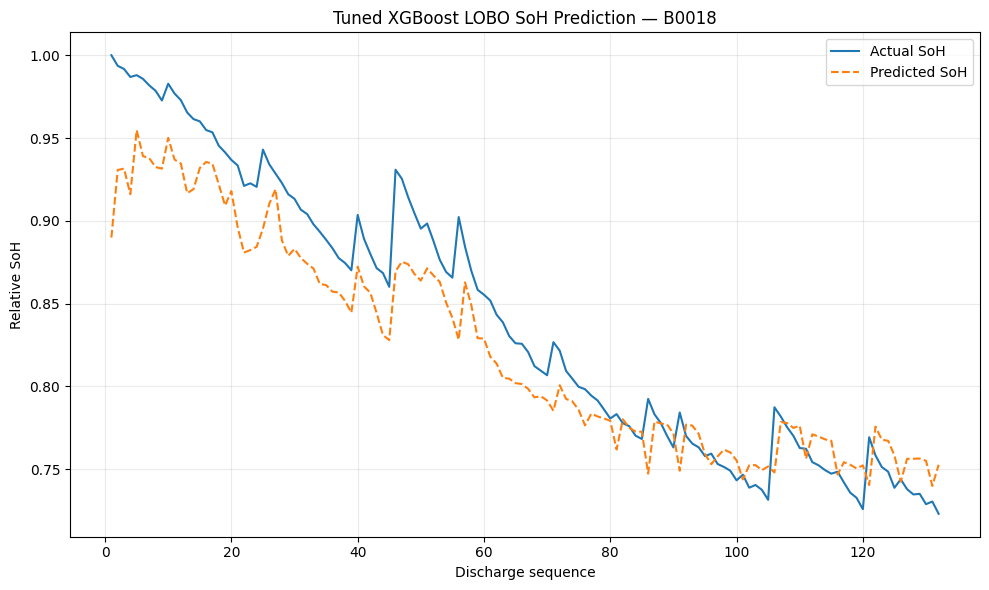

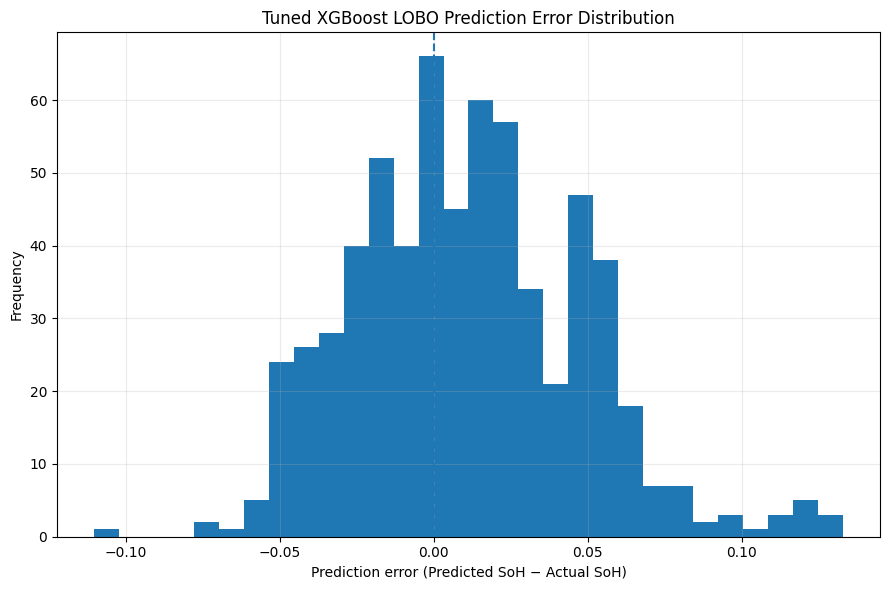

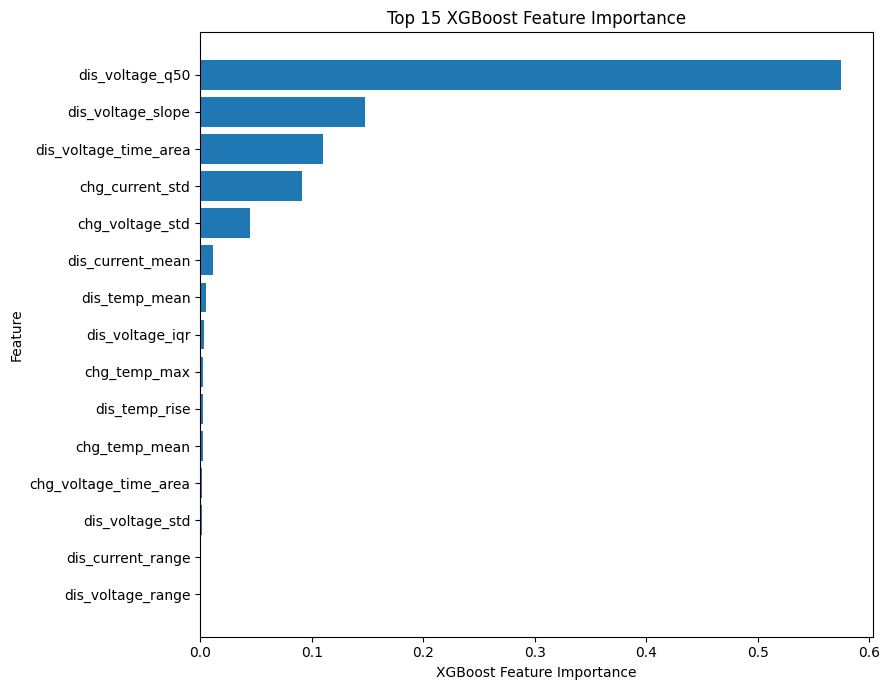


Overall XGBoost comparison:


,Model,Evaluation,MAE,RMSE,R2
0,XGBoost,Baseline holdout,0.005305,0.007495,0.994992
1,XGBoost,Tuned holdout,0.004289,0.006309,0.996452
2,XGBoost,Baseline LOBO,0.033233,0.040811,0.860382
3,XGBoost,Tuned LOBO,0.029843,0.038080,0.878439



Top XGBoost features:


,feature,xgboost_importance,rank
0,dis_voltage_q50,0.574734,1
1,dis_voltage_slope,0.147541,2
2,dis_voltage_time_area,0.110119,3
3,chg_current_std,0.091295,4
4,chg_voltage_std,0.044471,5
5,dis_current_mean,0.010990,6
6,dis_temp_mean,0.004993,7
7,dis_voltage_iqr,0.003713,8
8,chg_temp_max,0.002861,9
9,dis_temp_rise,0.002859,10


In [5]:
# XGBOOST BASELINE, TUNED, HOLDOUT, LOBO AND FEATURE IMPORTANCE


RANDOM_STATE = 42
TARGET = "soh_relative"
GROUP = "battery_id"
# LOAD DATA


feature_file = OUTPUT_DIR / "battery_soh_feature_dataset.csv"
reduced_file = OUTPUT_DIR / "automatic_reduced_feature_set.csv"

for file in [feature_file, reduced_file]:
    if not file.exists():
        raise FileNotFoundError(
            f"Required file not found: {file}"
        )

df = pd.read_csv(feature_file)

selected_features = pd.read_csv(
    reduced_file
)["feature"].tolist()

selected_features = [
    f for f in selected_features
    if f in df.columns
]

X = df[selected_features]
y = df[TARGET]

batteries = sorted(df[GROUP].unique())

print("XGBOOST MODELLING")
print(f"Dataset rows       : {len(df)}")
print(f"Reduced features   : {len(selected_features)}")
print(f"Batteries          : {batteries}")

print("\nSelected features:")
print(selected_features)


#  Helper functions


def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


def create_xgb(config):
    return XGBRegressor(
        **config,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )


# XGBoost configurations

configs = {

    "Baseline XGBoost": {
        "n_estimators": 100,
        "max_depth": 6,
        "learning_rate": 0.10,
        "subsample": 1.0,
        "colsample_bytree": 1.0,
        "min_child_weight": 1,
        "reg_alpha": 0,
        "reg_lambda": 1,
        "objective": "reg:squarederror",
        "eval_metric": "rmse"
    },

    "Tuned XGBoost": {
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 3,
        "reg_alpha": 0,
        "reg_lambda": 1,
        "objective": "reg:squarederror",
        "eval_metric": "rmse"
    }
}

for name, config in configs.items():
    print(f"\n{name}:")
    print(config)


#  CONVENTIONAL 80/20 HOLDOUT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

holdout_results = {}
holdout_models = {}

for name, config in configs.items():

    model = create_xgb(config)

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    holdout_results[name] = calculate_metrics(
        y_test,
        pred
    )

    holdout_models[name] = model


holdout_df = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Evaluation": "Baseline holdout",
        **holdout_results["Baseline XGBoost"]
    },
    {
        "Model": "XGBoost",
        "Evaluation": "Tuned holdout",
        **holdout_results["Tuned XGBoost"]
    }
])

holdout_file = OUTPUT_DIR / "xgboost_baseline_tuned_holdout.csv"
holdout_df.to_csv(holdout_file, index=False)

print("\nXGBOOST BASELINE VS TUNED HOLDOUT")
display(holdout_df.round(6))


# Holdout improvement

rmse_improvement = (
    (holdout_results["Baseline XGBoost"]["RMSE"]
     - holdout_results["Tuned XGBoost"]["RMSE"])
    / holdout_results["Baseline XGBoost"]["RMSE"]
    * 100
)

mae_improvement = (
    (holdout_results["Baseline XGBoost"]["MAE"]
     - holdout_results["Tuned XGBoost"]["MAE"])
    / holdout_results["Baseline XGBoost"]["MAE"]
    * 100
)

print("\nHOLDOUT IMPROVEMENT")
print(f"RMSE improvement: {rmse_improvement:.2f}%")
print(f"MAE improvement: {mae_improvement:.2f}%")


# LEAVE-ONE-BATTERY-OUT (LOBO)

lobo_metrics = []
lobo_predictions = []

for model_name, config in configs.items():

    print(f"\n{model_name}")
    print("-" * len(model_name))

    for test_battery in batteries:

        train_df = df[df[GROUP] != test_battery]
        test_df = df[df[GROUP] == test_battery]

        X_train = train_df[selected_features]
        y_train = train_df[TARGET]

        X_test = test_df[selected_features]
        y_test = test_df[TARGET]

        model = create_xgb(config)
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        test_metrics = calculate_metrics(
            y_test,
            test_pred
        )

        lobo_metrics.append({
            "model": model_name,
            "test_battery": test_battery,
            "train_batteries": ", ".join(
                b for b in batteries
                if b != test_battery
            ),
            "train_rows": len(train_df),
            "test_rows": len(test_df),
            "train_RMSE": np.sqrt(
                mean_squared_error(
                    y_train,
                    train_pred
                )
            ),
            "test_RMSE": test_metrics["RMSE"],
            "test_MAE": test_metrics["MAE"],
            "test_R2": test_metrics["R2"],
            "test_SoH_min": y_test.min(),
            "test_SoH_max": y_test.max()
        })

        prediction_frame = pd.DataFrame({
            "model": model_name,
            "battery_id": test_battery,
            "cycle_number": test_df["cycle_number"].to_numpy(),
            "discharge_sequence": test_df["discharge_sequence"].to_numpy(),
            "actual_soh": y_test.to_numpy(),
            "predicted_soh": test_pred
        })

        prediction_frame["prediction_error"] = (
            prediction_frame["predicted_soh"]
            - prediction_frame["actual_soh"]
        )

        prediction_frame["absolute_error"] = (
            prediction_frame["prediction_error"].abs()
        )

        lobo_predictions.append(prediction_frame)

        print(
            f"{test_battery}: "
            f"RMSE={test_metrics['RMSE']:.6f}, "
            f"MAE={test_metrics['MAE']:.6f}, "
            f"R²={test_metrics['R2']:.6f}"
        )


lobo_metrics_df = pd.DataFrame(lobo_metrics)

lobo_predictions_df = pd.concat(
    lobo_predictions,
    ignore_index=True
)

print("\nBATTERY-LEVEL XGBOOST LOBO RESULTS")
display(lobo_metrics_df.round(6))


# POOLED LOBO RESULTS

overall_results = []

for model_name, evaluation in [
    ("Baseline XGBoost", "Baseline LOBO"),
    ("Tuned XGBoost", "Tuned LOBO")
]:

    predictions = lobo_predictions_df[
        lobo_predictions_df["model"] == model_name
    ]

    metrics = calculate_metrics(
        predictions["actual_soh"],
        predictions["predicted_soh"]
    )

    overall_results.append({
        "Model": "XGBoost",
        "Evaluation": evaluation,
        **metrics
    })


overall_lobo_df = pd.DataFrame(overall_results)

print("\nOVERALL XGBOOST LOBO RESULTS")
display(overall_lobo_df.round(6))


# Save LOBO results


lobo_metrics_file = (
    OUTPUT_DIR /
    "xgboost_baseline_tuned_lobo_metrics.csv"
)

lobo_predictions_file = (
    OUTPUT_DIR /
    "xgboost_baseline_tuned_lobo_predictions.csv"
)

overall_lobo_file = (
    OUTPUT_DIR /
    "xgboost_baseline_tuned_lobo_overall.csv"
)

lobo_metrics_df.to_csv(
    lobo_metrics_file,
    index=False
)

lobo_predictions_df.to_csv(
    lobo_predictions_file,
    index=False
)

overall_lobo_df.to_csv(
    overall_lobo_file,
    index=False
)


# BASELINE VS TUNED LOBO IMPROVEMENT


baseline_lobo = overall_lobo_df[
    overall_lobo_df["Evaluation"] == "Baseline LOBO"
].iloc[0]

tuned_lobo = overall_lobo_df[
    overall_lobo_df["Evaluation"] == "Tuned LOBO"
].iloc[0]

lobo_rmse_improvement = (
    (baseline_lobo["RMSE"] - tuned_lobo["RMSE"])
    / baseline_lobo["RMSE"]
    * 100
)

lobo_mae_improvement = (
    (baseline_lobo["MAE"] - tuned_lobo["MAE"])
    / baseline_lobo["MAE"]
    * 100
)

print("\nBASELINE VS TUNED XGBOOST LOBO")
print(f"Baseline LOBO RMSE: {baseline_lobo['RMSE']:.6f}")
print(f"Tuned LOBO RMSE: {tuned_lobo['RMSE']:.6f}")
print(f"RMSE improvement: {lobo_rmse_improvement:.2f}%")
print(f"MAE improvement: {lobo_mae_improvement:.2f}%")


# FOUR-WAY COMPARISON
four_way = pd.concat(
    [
        holdout_df,
        overall_lobo_df
    ],
    ignore_index=True
)

evaluation_order = [
    "Baseline holdout",
    "Tuned holdout",
    "Baseline LOBO",
    "Tuned LOBO"
]

four_way["Evaluation"] = pd.Categorical(
    four_way["Evaluation"],
    categories=evaluation_order,
    ordered=True
)

four_way = (
    four_way
    .sort_values("Evaluation")
    .reset_index(drop=True)
)

four_way_file = (
    OUTPUT_DIR /
    "xgboost_four_way_comparison.csv"
)

four_way.to_csv(
    four_way_file,
    index=False
)

print("\nXGBOOST — OVERALL COMPARISON")
display(four_way.round(6))


#  FOUR-WAY RMSE PLOT

plt.figure(figsize=(10, 6))

plt.bar(
    four_way["Evaluation"],
    four_way["RMSE"]
)

plt.xlabel("Evaluation method")
plt.ylabel("RMSE")
plt.title("XGBoost Baseline and Tuned Performance")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

four_way_plot_file = (
    OUTPUT_DIR /
    "xgboost_four_way_rmse_comparison.png"
)

plt.savefig(
    four_way_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# TUNED LOBO ACTUAL VS PREDICTED

tuned_predictions = lobo_predictions_df[
    lobo_predictions_df["model"] == "Tuned XGBoost"
]

plt.figure(figsize=(9, 7))

plt.scatter(
    tuned_predictions["actual_soh"],
    tuned_predictions["predicted_soh"],
    alpha=0.65
)

min_value = min(
    tuned_predictions["actual_soh"].min(),
    tuned_predictions["predicted_soh"].min()
)

max_value = max(
    tuned_predictions["actual_soh"].max(),
    tuned_predictions["predicted_soh"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")
plt.title("Tuned XGBoost Leave-One-Battery-Out Predictions")
plt.grid(alpha=0.25)
plt.tight_layout()

scatter_file = (
    OUTPUT_DIR /
    "xgboost_lobo_actual_vs_predicted.png"
)

plt.savefig(
    scatter_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# BATTERY-LEVEL LOBO PLOTS

for battery in batteries:

    battery_results = (
        tuned_predictions[
            tuned_predictions["battery_id"] == battery
        ]
        .sort_values("discharge_sequence")
    )

    plt.figure(figsize=(10, 6))

    plt.plot(
        battery_results["discharge_sequence"],
        battery_results["actual_soh"],
        label="Actual SoH"
    )

    plt.plot(
        battery_results["discharge_sequence"],
        battery_results["predicted_soh"],
        linestyle="--",
        label="Predicted SoH"
    )

    plt.xlabel("Discharge sequence")
    plt.ylabel("Relative SoH")
    plt.title(
        f"Tuned XGBoost LOBO SoH Prediction — {battery}"
    )
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"xgboost_lobo_{battery}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# LOBO ERROR DISTRIBUTION

plt.figure(figsize=(9, 6))

plt.hist(
    tuned_predictions["prediction_error"],
    bins=30
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction error "
    "(Predicted SoH − Actual SoH)"
)

plt.ylabel("Frequency")
plt.title(
    "Tuned XGBoost LOBO Prediction Error Distribution"
)
plt.grid(alpha=0.25)
plt.tight_layout()

error_plot_file = (
    OUTPUT_DIR /
    "xgboost_lobo_error_distribution.png"
)

plt.savefig(
    error_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


#  FINAL XGBOOST MODEL - FEATURE IMPORTANCE


final_xgb = create_xgb(
    configs["Tuned XGBoost"]
)

final_xgb.fit(
    X,
    y
)

importance_df = pd.DataFrame({
    "feature": selected_features,
    "xgboost_importance": final_xgb.feature_importances_
})

importance_df = (
    importance_df
    .sort_values(
        "xgboost_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

importance_df["rank"] = (
    np.arange(len(importance_df)) + 1
)

importance_file = (
    OUTPUT_DIR /
    "xgboost_feature_importance.csv"
)

importance_df.to_csv(
    importance_file,
    index=False
)


# Top 15 importance plot

top_importance = (
    importance_df
    .head(15)
    .sort_values("xgboost_importance")
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_importance["feature"],
    top_importance["xgboost_importance"]
)

plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importance")
plt.tight_layout()

importance_plot_file = (
    OUTPUT_DIR /
    "thesis_xgboost_feature_importance.png"
)

plt.savefig(
    importance_plot_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


#  SAVE FINAL CONFIGURATION

configuration = pd.DataFrame({
    "parameter": [
        "feature_count",
        "n_estimators",
        "max_depth",
        "learning_rate",
        "subsample",
        "colsample_bytree",
        "min_child_weight",
        "reg_alpha",
        "reg_lambda",
        "objective",
        "eval_metric",
        "random_state"
    ],
    "value": [
        len(selected_features),
        300,
        4,
        0.03,
        0.8,
        0.8,
        3,
        0,
        1,
        "reg:squarederror",
        "rmse",
        RANDOM_STATE
    ]
})

configuration_file = (
    OUTPUT_DIR /
    "xgboost_final_configuration.csv"
)

configuration.to_csv(
    configuration_file,
    index=False
)


#  FINAL SUMMARY



print("\nOverall XGBoost comparison:")
display(four_way.round(6))

print("\nTop XGBoost features:")
display(importance_df.head(15).round(6))


Dataset rows   : 636
Final features : 24

Features used by final RF:
- dis_voltage_q10
- dis_voltage_q50
- dis_voltage_q90
- dis_voltage_iqr
- dis_voltage_range
- dis_voltage_std
- dis_voltage_slope
- dis_current_mean
- dis_current_std
- dis_current_range
- dis_temp_mean
- dis_temp_max
- dis_temp_rise
- dis_temp_slope
- dis_duration
- dis_voltage_time_area
- chg_voltage_mean
- chg_voltage_std
- chg_current_mean
- chg_current_std
- chg_temp_mean
- chg_temp_max
- chg_duration
- chg_voltage_time_area

Final Random Forest configuration:
n_estimators        : 300
max_depth           : 12
min_samples_leaf    : 2
max_features        : sqrt
random_state        : 42
n_jobs              : -1

Full-data fit metrics:
MAE  : 0.002235
RMSE : 0.004496
R²   : 0.998306

Random Forest feature importance:
 rank               feature  random_forest_importance
    1       dis_voltage_q50                  0.170071
    2       dis_voltage_q90                  0.150278
    3 dis_voltage_time_area             

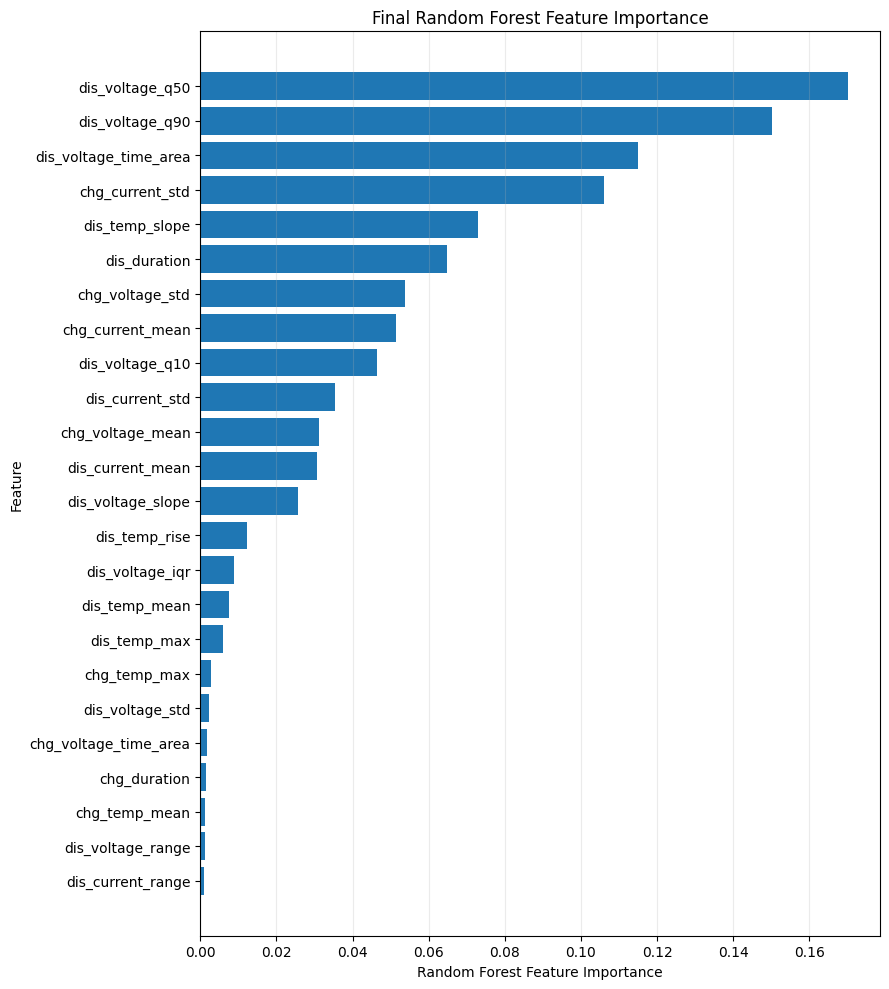


Calculating SHAP values...
SHAP calculation complete.
SHAP matrix shape: (636, 24)

Global SHAP feature importance:
 rank               feature  mean_abs_shap
    1       dis_voltage_q50       0.018443
    2       dis_voltage_q90       0.015081
    3 dis_voltage_time_area       0.012928
    4       chg_current_std       0.010778
    5        dis_temp_slope       0.008496
    6          dis_duration       0.007682
    7       dis_voltage_q10       0.005454
    8      chg_current_mean       0.004916
    9      dis_current_mean       0.004583
   10       chg_voltage_std       0.004578
   11       dis_current_std       0.004389
   12     dis_voltage_slope       0.002862
   13      chg_voltage_mean       0.002790
   14         dis_temp_rise       0.001693
   15       dis_voltage_iqr       0.001183
   16         dis_temp_mean       0.000850
   17          dis_temp_max       0.000830
   18       dis_voltage_std       0.000357
   19          chg_temp_max       0.000320
   20 chg_voltage_time_

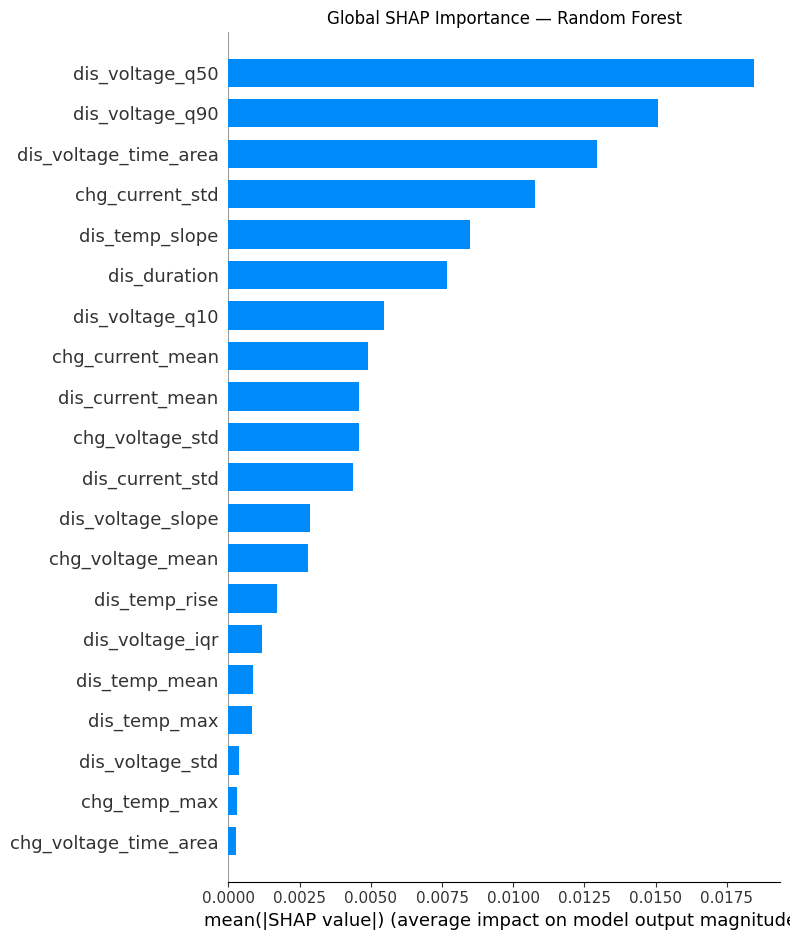

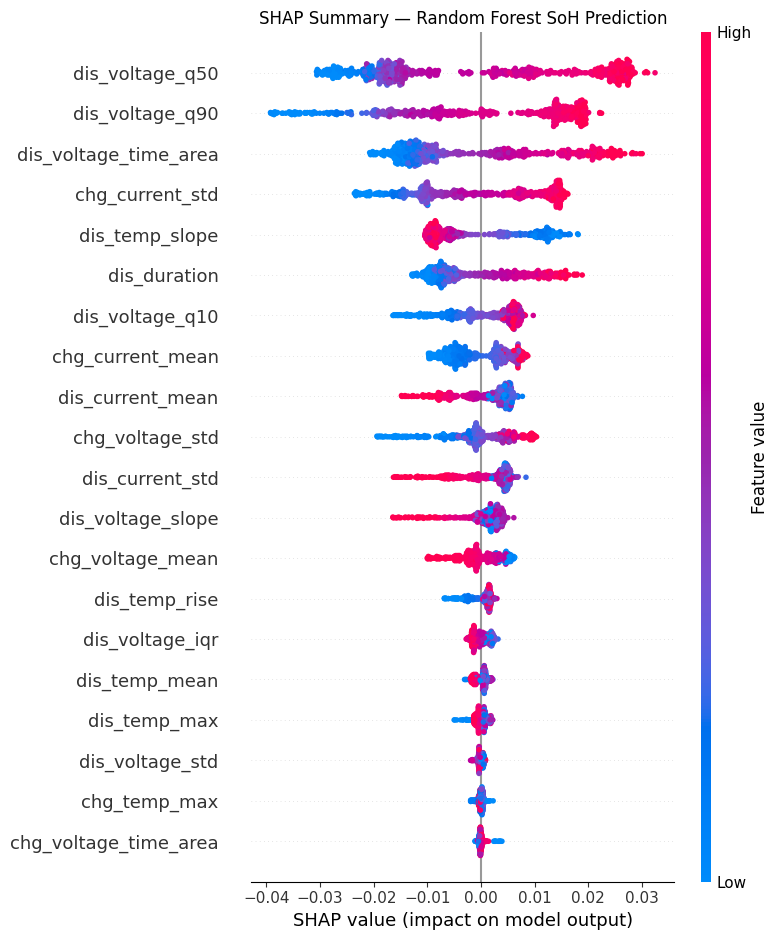


Top 5 SHAP features:
- dis_voltage_q50
- dis_voltage_q90
- dis_voltage_time_area
- chg_current_std
- dis_temp_slope


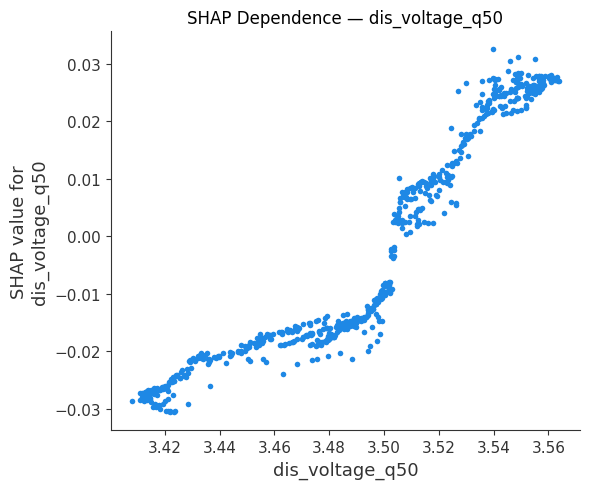

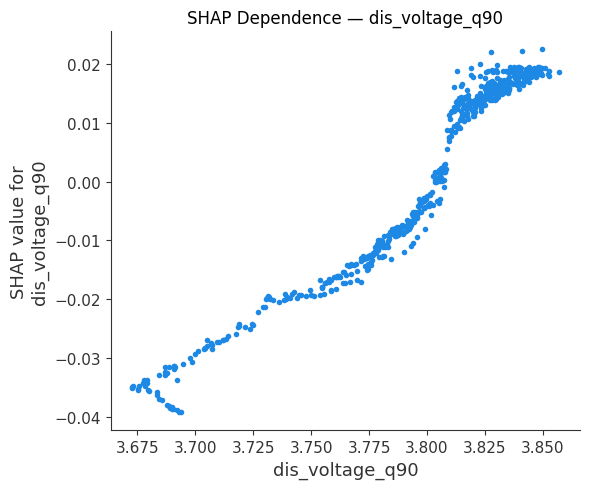

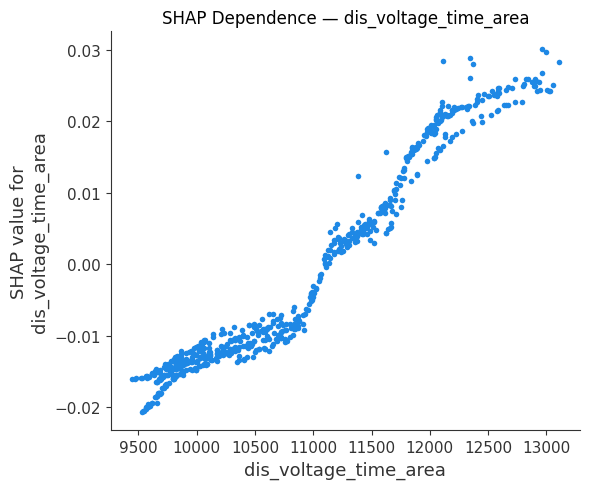

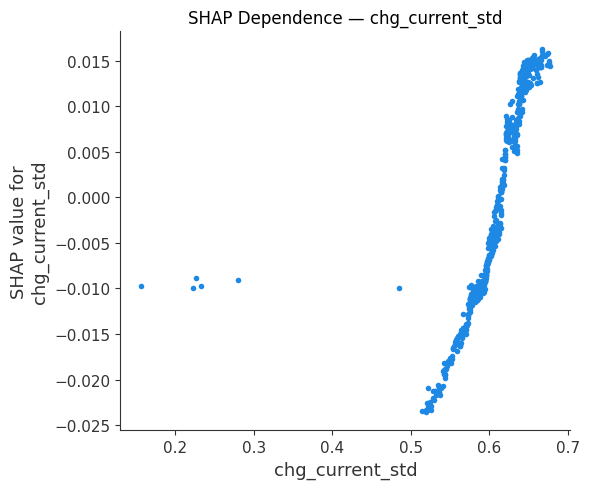

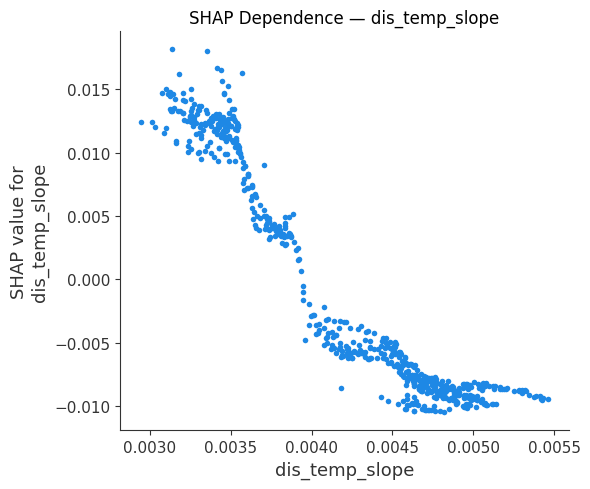


Low_SoH
Battery       : B0005
Cycle         : 604
Actual SoH    : 0.693785
Predicted SoH : 0.693616


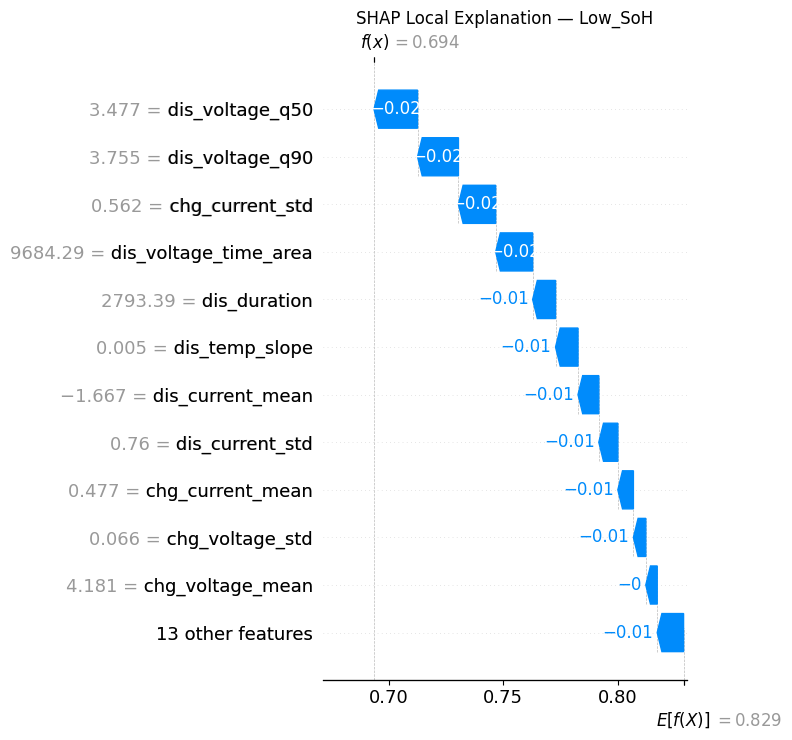


Medium_SoH
Battery       : B0005
Cycle         : 302
Actual SoH    : 0.823343
Predicted SoH : 0.821970


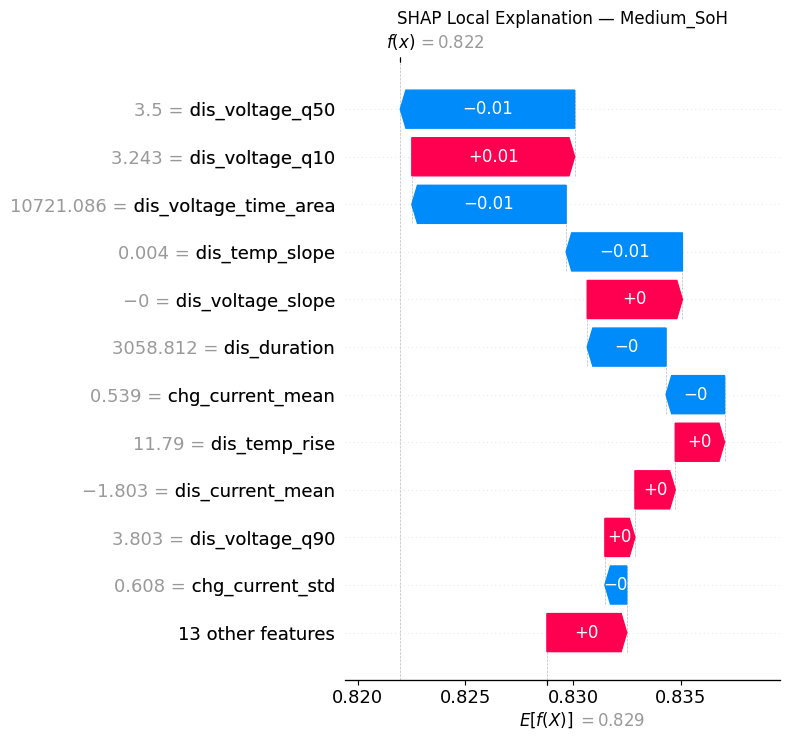


High_SoH
Battery       : B0018
Cycle         : 24
Actual SoH    : 0.978526
Predicted SoH : 0.974458


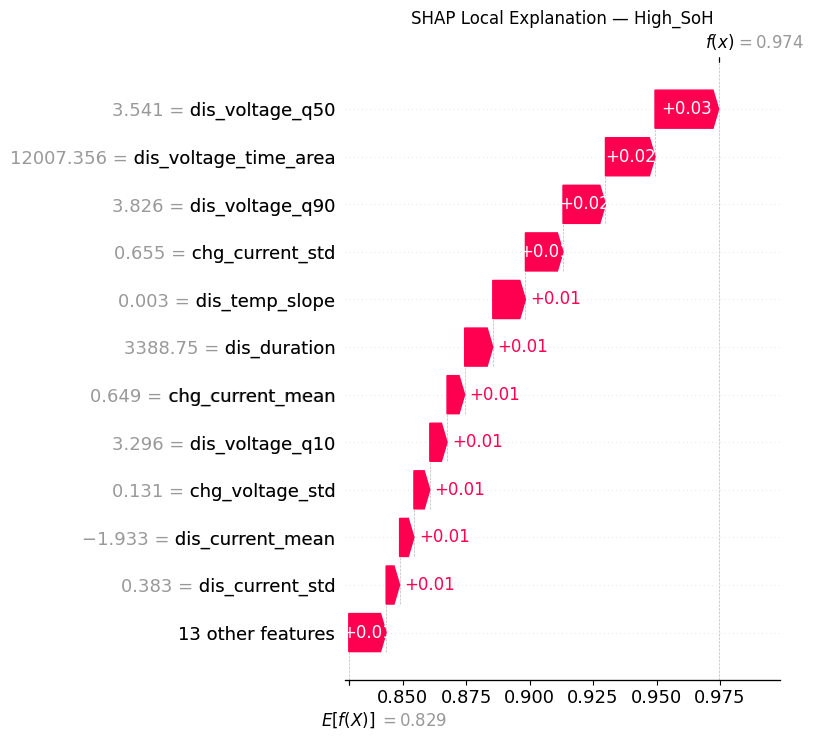


Prediction file loaded: /content/outputs/random_forest_baseline_tuned_lobo_predictions.csv
Tuned RF prediction rows: 636
Batteries: ['B0005', 'B0006', 'B0007', 'B0018']

Overall LOBO error statistics:
                metric     value
            Mean error  0.012532
   Mean absolute error  0.028265
                  RMSE  0.038594
Maximum absolute error  0.142675
         Minimum error -0.127769
         Maximum error  0.142675
             Std error  0.036531

Error statistics by battery:
battery_id  observations  mean_actual_soh  mean_predicted_soh  mean_error      MAE     RMSE  max_absolute_error
     B0005           168         0.847031            0.841033   -0.005998 0.009685 0.013542            0.063520
     B0006           168         0.759997            0.818410    0.058413 0.058915 0.064524            0.142675
     B0007           168         0.869580            0.866635   -0.002945 0.021552 0.026006            0.072311
     B0018           132         0.839729            0.8

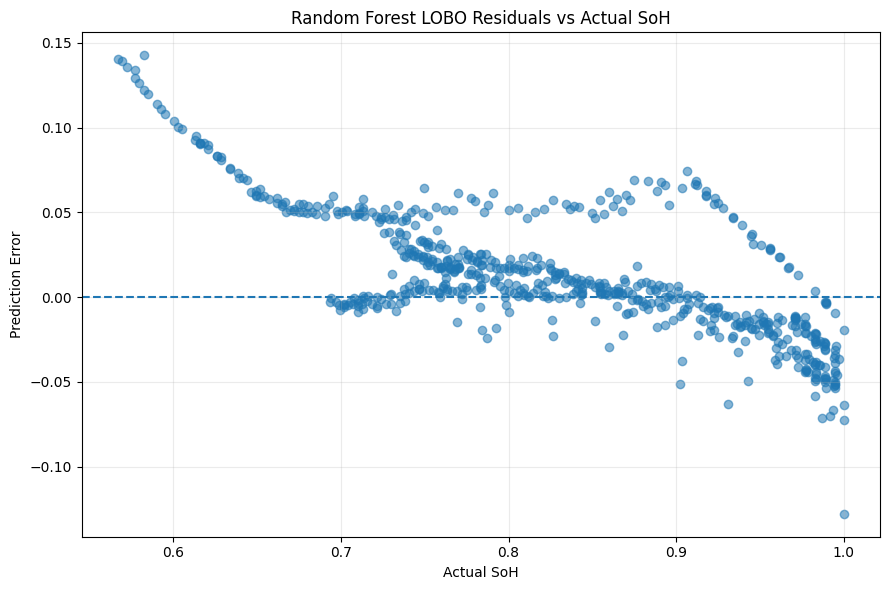

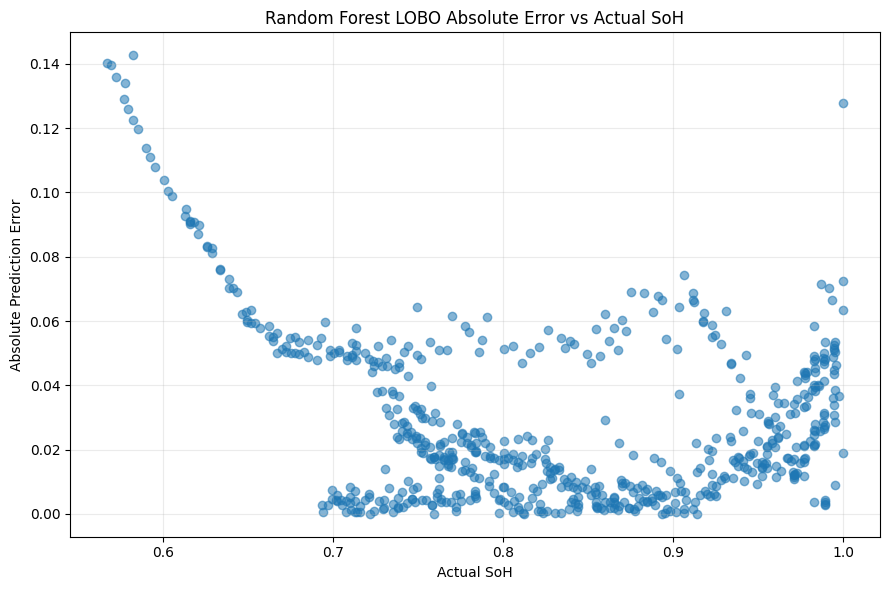

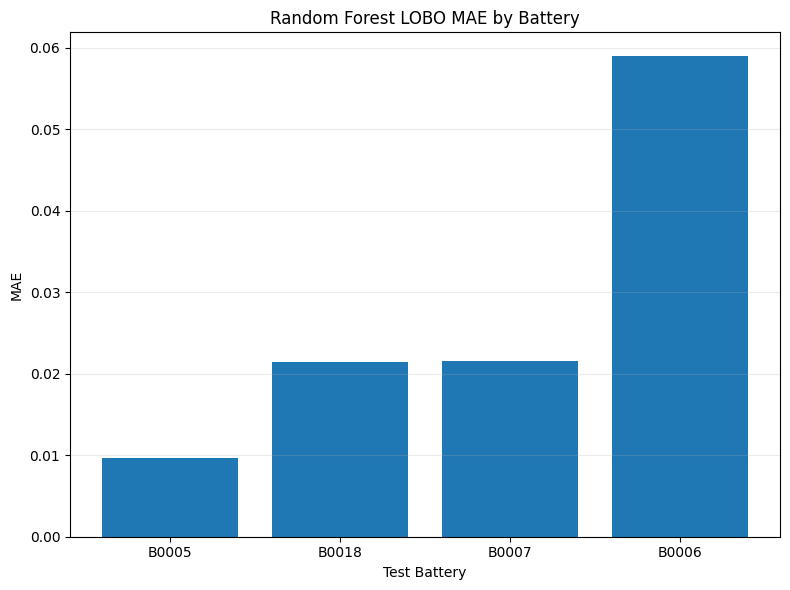

Overall mean error : 0.012532
Overall MAE        : 0.028265
Overall RMSE       : 0.038594

Prediction accuracy thresholds:
±0.02 SoH: 50.00%
±0.05 SoH: 79.56%
±0.10 SoH: 97.64%


In [6]:
# FINAL RANDOM FOREST - SHAP EXPLAINABILITY

# Load data and final selected feature set

DATA_FILE = OUTPUT_DIR / "battery_soh_feature_dataset.csv"
FEATURE_FILE = OUTPUT_DIR / "selected_random_forest_features.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Feature dataset not found:\n{DATA_FILE}")

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Selected RF feature file not found:\n{FEATURE_FILE}\n"
        "Please run the Random Forest modelling step first."
    )

df = pd.read_csv(DATA_FILE)

features = pd.read_csv(
    FEATURE_FILE
)["feature"].tolist()

features = [
    f for f in features
    if f in df.columns
]

target = "soh_relative"
group_column = "battery_id"

X = df[features].copy()
y = df[target].copy()

print(f"Dataset rows   : {len(df)}")
print(f"Final features : {len(features)}")
print("\nFeatures used by final RF:")

for feature in features:
    print(f"- {feature}")


#  Final Random Forest configuration

rf_config = {
    "n_estimators": 300,
    "max_depth": 12,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

print("\nFinal Random Forest configuration:")

for key, value in rf_config.items():
    print(f"{key:20s}: {value}")


# Fit final RF on all observations

final_rf = RandomForestRegressor(**rf_config)

final_rf.fit(X, y)

full_predictions = final_rf.predict(X)

full_mae = mean_absolute_error(y, full_predictions)
full_rmse = np.sqrt(
    mean_squared_error(y, full_predictions)
)
full_r2 = r2_score(y, full_predictions)

print("\nFull-data fit metrics:")
print(f"MAE  : {full_mae:.6f}")
print(f"RMSE : {full_rmse:.6f}")
print(f"R²   : {full_r2:.6f}")


# Save full-data training metrics

training_metrics = pd.DataFrame({
    "metric": ["MAE", "RMSE", "R2"],
    "value": [full_mae, full_rmse, full_r2]
})

training_metrics.to_csv(
    OUTPUT_DIR / "final_random_forest_training_metrics.csv",
    index=False
)


# Random Forest feature importance

importance_df = pd.DataFrame({
    "feature": features,
    "random_forest_importance": final_rf.feature_importances_
})

importance_df = (
    importance_df
    .sort_values(
        "random_forest_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

importance_df["rank"] = np.arange(
    1,
    len(importance_df) + 1
)

print("\nRandom Forest feature importance:")

print(
    importance_df[
        ["rank", "feature", "random_forest_importance"]
    ].to_string(index=False)
)

importance_df.to_csv(
    OUTPUT_DIR / "final_random_forest_feature_importance.csv",
    index=False
)


# Plot Random Forest feature importance

plot_importance = importance_df.sort_values(
    "random_forest_importance",
    ascending=True
)

plt.figure(figsize=(9, 10))

plt.barh(
    plot_importance["feature"],
    plot_importance["random_forest_importance"]
)

plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title("Final Random Forest Feature Importance")

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# SHAP EXPLAINABILITY


print("\nCalculating SHAP values...")

explainer = shap.TreeExplainer(final_rf)

shap_values = explainer.shap_values(X)

shap_values_array = np.asarray(shap_values)

print("SHAP calculation complete.")
print(f"SHAP matrix shape: {shap_values_array.shape}")


# Global SHAP importance

mean_abs_shap = np.abs(
    shap_values_array
).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "feature": features,
    "mean_abs_shap": mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance_df["rank"] = np.arange(
    1,
    len(shap_importance_df) + 1
)

print("\nGlobal SHAP feature importance:")

print(
    shap_importance_df[
        ["rank", "feature", "mean_abs_shap"]
    ].to_string(index=False)
)

shap_importance_df.to_csv(
    OUTPUT_DIR / "final_random_forest_shap_importance.csv",
    index=False
)


# SHAP summary bar plot

shap.summary_plot(
    shap_values_array,
    X,
    plot_type="bar",
    show=False
)

plt.title("Global SHAP Importance — Random Forest")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_random_forest_shap_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# SHAP beeswarm plot

shap.summary_plot(
    shap_values_array,
    X,
    show=False
)

plt.title("SHAP Summary — Random Forest SoH Prediction")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_random_forest_shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# SHAP dependence plots for top 5 features

top_features = (
    shap_importance_df
    .head(5)["feature"]
    .tolist()
)

print("\nTop 5 SHAP features:")

for feature in top_features:
    print(f"- {feature}")

for feature in top_features:

    shap.dependence_plot(
        feature,
        shap_values_array,
        X,
        interaction_index=None,
        show=False
    )

    plt.title(f"SHAP Dependence — {feature}")
    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    plt.savefig(
        OUTPUT_DIR / f"shap_dependence_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


#  Representative low, medium and high SoH observations
soh_sorted = df[target].sort_values()

low_index = soh_sorted.index[
    int(len(soh_sorted) * 0.10)
]

medium_index = soh_sorted.index[
    int(len(soh_sorted) * 0.50)
]

high_index = soh_sorted.index[
    int(len(soh_sorted) * 0.90)
]

representative_cases = [
    (low_index, "Low_SoH"),
    (medium_index, "Medium_SoH"),
    (high_index, "High_SoH")
]


# Local SHAP explanations

local_records = []

for index, label in representative_cases:

    row_position = X.index.get_loc(index)

    actual_value = y.loc[index]
    predicted_value = full_predictions[row_position]

    print(f"\n{label}")
    print(f"Battery       : {df.loc[index, group_column]}")
    print(f"Cycle         : {df.loc[index, 'cycle_number']}")
    print(f"Actual SoH    : {actual_value:.6f}")
    print(f"Predicted SoH : {predicted_value:.6f}")

    row_shap = shap_values_array[row_position]

    local_df = pd.DataFrame({
        "feature": features,
        "feature_value": X.loc[index].values,
        "shap_value": row_shap
    })

    local_df["abs_shap"] = np.abs(
        local_df["shap_value"]
    )

    local_df = local_df.sort_values(
        "abs_shap",
        ascending=False
    )

    local_df["case"] = label
    local_df["battery_id"] = df.loc[
        index, group_column
    ]
    local_df["cycle_number"] = df.loc[
        index, "cycle_number"
    ]
    local_df["actual_soh"] = actual_value
    local_df["predicted_soh"] = predicted_value

    local_records.append(local_df)

    # SHAP waterfall explanation
    explanation = shap.Explanation(
        values=row_shap,
        base_values=explainer.expected_value,
        data=X.loc[index].values,
        feature_names=features
    )

    shap.plots.waterfall(
        explanation,
        max_display=12,
        show=False
    )

    plt.title(
        f"SHAP Local Explanation — {label}"
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"shap_waterfall_{label}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# Save local SHAP explanations

local_shap_df = pd.concat(
    local_records,
    ignore_index=True
)

local_shap_df.to_csv(
    OUTPUT_DIR /
    "final_random_forest_local_shap_explanations.csv",
    index=False
)


# Save complete SHAP matrix

shap_matrix_df = pd.DataFrame(
    shap_values_array,
    columns=features,
    index=df.index
)

shap_matrix_df.insert(
    0,
    "battery_id",
    df[group_column].values
)

shap_matrix_df.insert(
    1,
    "cycle_number",
    df["cycle_number"].values
)

shap_matrix_df.insert(
    2,
    "actual_soh",
    y.values
)

shap_matrix_df.insert(
    3,
    "predicted_soh",
    full_predictions
)

shap_matrix_df.to_csv(
    OUTPUT_DIR /
    "final_random_forest_shap_values.csv",
    index=False
)



#  LOBO ERROR ANALYSIS AND ROBUSTNESS CHECK

PREDICTION_FILE = (
    OUTPUT_DIR /
    "random_forest_baseline_tuned_lobo_predictions.csv"
)

if not PREDICTION_FILE.exists():
    raise FileNotFoundError(
        f"Required prediction file not found:\n"
        f"{PREDICTION_FILE}\n\n"
        "Please run the Random Forest LOBO step first."
    )

pred_df = pd.read_csv(PREDICTION_FILE)

print(
    f"\nPrediction file loaded: {PREDICTION_FILE}"
)


#  Select tuned Random Forest predictions
if "model" not in pred_df.columns:
    raise ValueError(
        "The prediction file does not contain a 'model' column."
    )

TUNED_MODEL_NAME = "Tuned Random Forest"

if TUNED_MODEL_NAME not in pred_df["model"].unique():
    raise ValueError(
        f"'{TUNED_MODEL_NAME}' was not found.\n"
        f"Available models: "
        f"{sorted(pred_df['model'].unique())}"
    )

pred_df = pred_df[
    pred_df["model"] == TUNED_MODEL_NAME
].copy()


# Check required columns

required_columns = [
    "battery_id",
    "actual_soh",
    "predicted_soh"
]

missing_columns = [
    column
    for column in required_columns
    if column not in pred_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print(
    f"Tuned RF prediction rows: {len(pred_df)}"
)

print(
    f"Batteries: "
    f"{sorted(pred_df['battery_id'].unique())}"
)


# Calculate prediction errors

pred_df["error"] = (
    pred_df["predicted_soh"]
    - pred_df["actual_soh"]
)

pred_df["absolute_error"] = (
    pred_df["error"].abs()
)

pred_df["squared_error"] = (
    pred_df["error"] ** 2
)


# Classify observations by actual SoH

def assign_soh_range(soh):

    if soh >= 0.90:
        return "High_SoH"

    if soh >= 0.75:
        return "Medium_SoH"

    return "Low_SoH"


pred_df["soh_range"] = (
    pred_df["actual_soh"]
    .apply(assign_soh_range)
)


# Overall error statistics

overall_error = pd.DataFrame({
    "metric": [
        "Mean error",
        "Mean absolute error",
        "RMSE",
        "Maximum absolute error",
        "Minimum error",
        "Maximum error",
        "Std error"
    ],
    "value": [
        pred_df["error"].mean(),
        pred_df["absolute_error"].mean(),
        np.sqrt(
            pred_df["squared_error"].mean()
        ),
        pred_df["absolute_error"].max(),
        pred_df["error"].min(),
        pred_df["error"].max(),
        pred_df["error"].std()
    ]
})

print("\nOverall LOBO error statistics:")

print(
    overall_error.to_string(index=False)
)


#  Error statistics by battery

battery_error = (
    pred_df
    .groupby("battery_id")
    .agg(
        observations=("actual_soh", "size"),
        mean_actual_soh=("actual_soh", "mean"),
        mean_predicted_soh=("predicted_soh", "mean"),
        mean_error=("error", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=(
            "squared_error",
            lambda x: np.sqrt(x.mean())
        ),
        max_absolute_error=("absolute_error", "max")
    )
    .reset_index()
)

print("\nError statistics by battery:")

print(
    battery_error.to_string(index=False)
)


# Error statistics by SoH range
soh_range_error = (
    pred_df
    .groupby("soh_range")
    .agg(
        observations=("actual_soh", "size"),
        mean_actual_soh=("actual_soh", "mean"),
        mean_error=("error", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=(
            "squared_error",
            lambda x: np.sqrt(x.mean())
        ),
        max_absolute_error=("absolute_error", "max")
    )
    .reset_index()
)

range_order = [
    "High_SoH",
    "Medium_SoH",
    "Low_SoH"
]

soh_range_error["soh_range"] = pd.Categorical(
    soh_range_error["soh_range"],
    categories=range_order,
    ordered=True
)

soh_range_error = (
    soh_range_error
    .sort_values("soh_range")
    .reset_index(drop=True)
)

print("\nError statistics by SoH range:")

print(
    soh_range_error.to_string(index=False)
)


#  Prediction accuracy thresholds


thresholds = [0.02, 0.05, 0.10]

threshold_rows = []

for threshold in thresholds:

    count = (
        pred_df["absolute_error"] <= threshold
    ).sum()

    percentage = (
        count / len(pred_df)
    ) * 100

    threshold_rows.append({
        "threshold": f"±{threshold:.2f} SoH",
        "number_predictions": count,
        "percentage": percentage
    })

threshold_results = pd.DataFrame(
    threshold_rows
)

print("\nPrediction accuracy thresholds:")

print(
    threshold_results.to_string(index=False)
)


#  Largest prediction errors

largest_errors = (
    pred_df
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
    .copy()
)

print("\n20 largest LOBO prediction errors:")

display_columns = [
    "battery_id",
    "actual_soh",
    "predicted_soh",
    "error",
    "absolute_error"
]

print(
    largest_errors[
        display_columns
    ].to_string(index=False)
)


#  LOBO ERROR PLOTS

# Residuals vs actual SoH
plt.figure(figsize=(9, 6))

plt.scatter(
    pred_df["actual_soh"],
    pred_df["error"],
    alpha=0.55
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Actual SoH")
plt.ylabel("Prediction Error")

plt.title(
    "Random Forest LOBO Residuals vs Actual SoH"
)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "random_forest_lobo_residuals_vs_soh.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Absolute error vs actual SoH
plt.figure(figsize=(9, 6))

plt.scatter(
    pred_df["actual_soh"],
    pred_df["absolute_error"],
    alpha=0.55
)

plt.xlabel("Actual SoH")
plt.ylabel("Absolute Prediction Error")

plt.title(
    "Random Forest LOBO Absolute Error vs Actual SoH"
)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "random_forest_lobo_absolute_error_vs_soh.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# MAE by battery
plot_battery = battery_error.sort_values(
    "MAE",
    ascending=True
)

plt.figure(figsize=(8, 6))

plt.bar(
    plot_battery["battery_id"],
    plot_battery["MAE"]
)

plt.xlabel("Test Battery")
plt.ylabel("MAE")

plt.title(
    "Random Forest LOBO MAE by Battery"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "random_forest_lobo_mae_by_battery.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# SAVE LOBO ERROR RESULTS


overall_error.to_csv(
    OUTPUT_DIR /
    "random_forest_lobo_error_statistics.csv",
    index=False
)

battery_error.to_csv(
    OUTPUT_DIR /
    "random_forest_lobo_error_by_battery.csv",
    index=False
)

soh_range_error.to_csv(
    OUTPUT_DIR /
    "random_forest_lobo_error_by_soh_range.csv",
    index=False
)

threshold_results.to_csv(
    OUTPUT_DIR /
    "random_forest_lobo_accuracy_thresholds.csv",
    index=False
)

largest_errors.to_csv(
    OUTPUT_DIR /
    "random_forest_lobo_largest_errors.csv",
    index=False
)

pred_df.to_csv(
    OUTPUT_DIR /
    "random_forest_lobo_predictions_with_errors.csv",
    index=False
)


# Final summary


overall_mae = pred_df["absolute_error"].mean()

overall_rmse = np.sqrt(
    pred_df["squared_error"].mean()
)

overall_mean_error = pred_df["error"].mean()


print(
    f"Overall mean error : {overall_mean_error:.6f}"
)

print(
    f"Overall MAE        : {overall_mae:.6f}"
)

print(
    f"Overall RMSE       : {overall_rmse:.6f}"
)

print("\nPrediction accuracy thresholds:")

for row in threshold_rows:

    print(
        f"{row['threshold']}: "
        f"{row['percentage']:.2f}%"
    )